# Planificación de velocidad y trayectoria para un agente autónomo en Tocancipá (Assetto Corsa)

**Física A: Hardware e Información · Proyecto final**

**Integrantes:** John Edward Rincón Aragón (202420895) · Samuel Zuluaga (202520012) · Samuel Eduardo Beltrán López (202522601)

**Pregunta de investigación.** ¿En qué medida un modelo simplificado de un vehículo permite predecir y optimizar trayectorias de conducción que mantengan un buen rendimiento y estabilidad al ejecutarse en un entorno de simulación con física vehicular más detallada?

**Cómo la respondemos.** El modelo simplificado es una bicicleta cinemática con límite de agarre, potencia y frenado; el entorno detallado es Assetto Corsa, en el Autódromo de Tocancipá. Medimos el **rendimiento** con el tiempo de vuelta (predicho frente a real) y la **estabilidad** con tres indicadores: que el auto complete vueltas sin salirse, que no pida más agarre del disponible y que repita el mismo tiempo vuelta tras vuelta.

**Idea central.** Un modelo de bicicleta cinemática con un límite de agarre (círculo de fricción), un límite de potencia y un frenado constante basta para calcular, antes de arrancar, una trayectoria y un perfil de velocidad. Un agente conductor sigue ese plan en Assetto Corsa a 50 Hz. Medimos en el simulador la aceleración y el frenado reales del auto, validamos el método numérico con casos analíticos y comparamos lo que predice el modelo con lo que hace el auto en el juego.

## Cómo está organizado este notebook

Cada bloque de código va precedido de una explicación (qué hace y por qué) y seguido de una interpretación de su resultado.

| Sección | Contenido |
|---|---|
| 0 | Preparación: librerías, módulos del proyecto y datos |
| 1 | Contexto: el problema, Assetto Corsa, la conexión con ISC y la arquitectura del sistema |
| 2 | Modelo físico: aspectos considerados, ecuaciones (con su ubicación en el código), simplificaciones y fenómenos omitidos |
| 3 | Parámetros del vehículo |
| 4 | Mediciones propias en Assetto Corsa: aceleración y frenado reales |
| 5 | Geometría del circuito y la pista como integral de su curvatura |
| 6 | Perfil de velocidad, ápices geométricos y trayectoria optimizada |
| 7 | Simulación en el tiempo: el agente conduce el modelo de bicicleta |
| 8 | Validación del método numérico y efecto del paso de tiempo |
| 9 | Análisis complementario: visibilidad necesaria para frenar |
| 10 | Sensibilidad a los parámetros |
| 11 | Comparación con 3 vueltas reales en Assetto Corsa |
| 12–15 | Limitaciones, conclusiones, declaración de uso de IA y referencias |

## 0. Preparación

**Librerías.** El notebook solo usa NumPy y Matplotlib (más la librería estándar de Python). Si faltan: `pip install numpy matplotlib`.

**Módulos del proyecto.** Toda la física está escrita por nosotros en la carpeta `proy entrega final/`, y el notebook **importa esos mismos archivos**: las ecuaciones que se ejecutan aquí son exactamente las que usa el agente en Assetto Corsa. Los que importan para el modelo físico son:

| Archivo | Qué hace |
|---|---|
| `modelado_fisico.py` | Geometría y estimación de la pista (curvatura, normales, integración de la curvatura), bicicleta cinemática, límites de agarre, potencia y frenado |
| `estimaciones.py` | **La parte central:** perfil de velocidad (pasadas hacia atrás y hacia adelante), tiempo de una trayectoria y huella rectangular |
| `conducir_fisica_optimizado.py` | Ápices geométricos y optimización de la trayectoria (y el bucle de conducción en vivo) |
| `agente_conductor.py` | Agente conductor: convierte el plan en volante, acelerador y freno sin cambios imposibles |

El resto de archivos conecta el programa con Assetto Corsa (telemetría, joystick virtual, comparador); la sección 1.4 resume cómo.

**Funciona sin el juego abierto.** El módulo de conducción importa `pyvjoy`, la librería del joystick virtual, que solo existe en Windows con vJoy instalado. Como el notebook nunca envía mandos, registramos un módulo vacío con ese nombre para que la importación no falle. Ninguna celda se conecta a Assetto Corsa: todo lo que viene del simulador se lee de archivos ya guardados.

In [1]:
import sys, types, json, inspect
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
CODIGO = RAIZ / "proy entrega final"
DATOS = RAIZ / "datos"
sys.path.insert(0, str(CODIGO))
sys.modules.setdefault("pyvjoy", types.ModuleType("pyvjoy"))   # vJoy no se usa en el notebook

import modelado_fisico as mf
import estimaciones as est
import gestor_circuito as gc
import geometria_circuito as geo
import conducir_fisica_optimizado as cfo
from agente_conductor import AgenteConductor

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "font.size": 11})
G = mf.G
ARCHIVO_PLAN = CODIGO / "comparador_fisica_assetto" / "plan_compartido.json"
PLAN = json.loads(ARCHIVO_PLAN.read_text(encoding="utf-8")) if ARCHIVO_PLAN.exists() else None
print("Módulos del proyecto cargados desde:", CODIGO)

Módulos del proyecto cargados desde: /home/claude/proyecto_fisica/proy entrega final


**Interpretación.** Si esta celda corre sin errores, el notebook está usando el código real del proyecto. Si se ejecuta desde otra carpeta, hay que abrir el notebook en la raíz del repositorio (donde está la carpeta `proy entrega final/`).

### 0.1 Datos de Assetto Corsa que usa el notebook

Todo lo que viene del simulador se lee de archivos guardados en el repositorio, generados en el computador donde corre el juego:

| Dato | Archivo | Se usa en |
|---|---|---|
| Geometría de Tocancipá ya preparada, ruta optimizada en vivo y parámetros del auto | `proy entrega final/comparador_fisica_assetto/plan_compartido.json` | Secciones 3, 5, 6 y 11 |
| Medición de aceleración y frenado en recta | `proy entrega final/medicion_ac_vjoy/20261125_133617/muestras.csv` | Sección 4 |
| Telemetría de 3 vueltas del agente en Assetto Corsa (~50 muestras por segundo) | `proy entrega final/datos/telemetria_ac.csv` | Sección 11 |

Si `plan_compartido.json` faltara, el notebook usa un circuito de prueba y parámetros por defecto, y lo avisa; así se ejecuta siempre de principio a fin.

In [2]:
ARCHIVO_TELEMETRIA = CODIGO / "datos" / "telemetria_ac.csv"
for nombre, archivo in [("plan del programa en vivo", ARCHIVO_PLAN), ("telemetría de Assetto Corsa", ARCHIVO_TELEMETRIA)]:
    print(f"{'✔' if archivo.exists() else '✘ falta'}  {nombre}: {archivo.relative_to(RAIZ)}")

✔  plan del programa en vivo: proy entrega final/comparador_fisica_assetto/plan_compartido.json
✔  telemetría de Assetto Corsa: proy entrega final/datos/telemetria_ac.csv


## 1. Contexto

### 1.1 El problema

Queremos que un vehículo complete vueltas rápidas y válidas en el Autódromo de Tocancipá dentro de Assetto Corsa, controlado por un programa y no por una persona. Para eso hay que decidir, en cada punto de la pista, **por dónde pasar** (trayectoria), **qué tan rápido ir** (perfil de velocidad) y **cuándo frenar** para llegar a cada curva a una velocidad que el agarre de los neumáticos permita.

Nuestro enfoque separa dos tareas:

1. **Planificar (física).** Antes de arrancar, un modelo físico reducido calcula una trayectoria y un perfil de velocidad para toda la vuelta.
2. **Ejecutar (control).** Durante la vuelta, un agente conductor lee la telemetría del simulador 50 veces por segundo y convierte el plan en acelerador, freno y dirección.

Distinguimos siempre tres cosas: lo que **recomienda** el modelo, lo que **pide** el agente y lo que **hace** el auto en el simulador.

### 1.2 Assetto Corsa y Tocancipá

Assetto Corsa es un simulador de carreras desarrollado por Kunos Simulazioni, un estudio italiano, y lanzado para PC en diciembre de 2014. Su motor de física simula con detalle los neumáticos (temperatura, desgaste y puntos planos), la suspensión y la aerodinámica, y sus pistas oficiales fueron reproducidas con escaneo láser. Además, admite contenido creado por la comunidad: el Autódromo de Tocancipá no es una pista oficial, sino un mod hecho desde cero para la Asociación de Pilotos Virtuales Sudamericanos (APVS). El simulador también se ha usado en investigación de conducción autónoma (por ejemplo, la plataforma Assetto Corsa Gym, de 2024), porque permite leer en tiempo real el estado del vehículo y enviarle controles, que es justo lo que necesita nuestro agente.

En cuanto al realismo, el juego trae perfiles de ayudas (Gamer, Racer, Pro y uno personalizado) que van desde ayudas artificiales hasta ayudas de fábrica o ninguna. Usamos la configuración más exigente que permite el simulador, con la caja automática y las mismas ayudas en todas las pruebas. En ese modo, Assetto Corsa modela fenómenos que nosotros omitimos, como la transferencia de peso, los neumáticos reales y la aerodinámica, así que lo usamos como una referencia más detallada para medir los errores de nuestro modelo. Aun así, sigue siendo un modelo y no un auto real: la precisión de la pista depende del autor del mod, y un buen resultado en el simulador no demuestra por sí solo validez en la vida real. Un dato que respalda nuestra simplificación en 2D es que el circuito real mide unos 2,72 km, tiene 14 curvas y un desnivel de solo unos 9 m.

### 1.3 Conexión con Ingeniería de Sistemas y Computación

- **Agente autónomo con un modelo del mundo.** El agente sigue el ciclo percepción → decisión → acción: lee el estado del auto, consulta el plan y responde con mandos. El modelo físico es su "modelo del mundo": tiene que ser lo bastante simple para evaluarse cientos de veces durante la optimización (cada evaluación de una vuelta tarda centésimas de segundo) y lo bastante fiel para que el plan sea ejecutable.
- **Sistema de tiempo real.** El bucle de control corre cada $20$ ms. Todo el cálculo de un ciclo (leer memoria compartida, proyectar la posición sobre la trayectoria, calcular mandos y enviarlos) debe caber en ese intervalo; por eso la optimización, que es costosa, se hace una sola vez antes de arrancar.
- **Integración de software con un sistema externo.** Leemos estructuras binarias de la memoria compartida de Assetto Corsa con `ctypes` y `mmap`, y escribimos en un joystick virtual (vJoy). Es el mismo problema de interfaz hardware/software que aparece al controlar un robot o un vehículo real a través de sus sensores y actuadores.
- **Compromiso precisión–costo.** El paso de tiempo $\Delta t$ y la resolución de la pista (1500 puntos) fijan cuántas operaciones hacemos por segundo simulado y cuánto error numérico aceptamos (sección 8).
- **Planificación como optimización.** Buscar la trayectoria es un problema de optimización con restricciones (agarre, ancho de pista, huella del auto) resuelto con una búsqueda local sobre candidatos.

### 1.4 Arquitectura del sistema en vivo

```
                 ┌──────────────────── ANTES DE ARRANCAR ────────────────────┐
 side_l.csv  ─┐  │ geometria_circuito → gestor_circuito → optimizar()         │
 side_r.csv  ─┘  │ (bordes → centro)    (vuelta + márgenes)  evaluar_trayectoria│ → ruta + perfil v(s)
 car.ini, tyres.ini → leer_parametros_ac → Vehiculo(m, P, L, μ, a_max, b_max) │
                 └────────────────────────────────────────────────────────────┘
                 ┌──────────────── CADA 20 ms (50 Hz) ────────────────┐
 Assetto Corsa ──► memoria compartida ──► telemetria_assetto ──► convertir_estado (x, y, ψ, v)
      ▲                                                               │
      │                                    progreso s sobre la ruta ◄─┘
      │                                                │
      └── vJoy (volante, acelerador, freno) ◄── convertir_controles ◄── AgenteConductor
                                                                  (v objetivo, δ del plan + corrección)
```

En el notebook reproducimos todo lo que está fuera del simulador: la geometría, la optimización y el agente. Para cerrar el lazo sin el juego, reemplazamos Assetto Corsa por nuestro propio modelo de bicicleta (sección 7).

## 2. Modelo físico

### 2.1 Aspectos que consideramos y por qué


**Masa del vehículo.** La incluimos porque relaciona fuerza y aceleración (F = m·a). Cuando el agarre es el límite, la masa se cancela: a_max = μg. Por eso, en nuestro modelo la distancia de frenado y la velocidad en curva no dependen de la masa. Sí importa cuando el límite es la potencia del motor, porque un auto más pesado acelera más lento en recta.

**Potencia útil del motor.** A alta velocidad, la fuerza de tracción disponible es F = P/v. Por eso la aceleración cae a medida que el auto va más rápido (a = P/(m·v)). Con ella el modelo distingue la salida de una curva, donde manda el agarre, del final de una recta, donde manda el motor, y estima mejor cuánta velocidad se gana antes de la siguiente frenada.

**Aceleración máxima.** Es el tope de aceleración longitudinal, sea por agarre o por motor. Sin ella, el perfil de velocidad podría subir de forma irreal entre curvas. Con ella, el tiempo estimado en cada recta tiene sentido físico.

**Frenado máximo.** Es la variable central de nuestra pregunta. Con una desaceleración máxima a_f, la distancia para bajar de v₀ a la velocidad de la curva v_c es d = (v₀² − v_c²) / (2·a_f). Si a_f está mal estimada, el agente frena tarde y se sale, o frena antes de tiempo y pierde tiempo.

**Fricción entre neumáticos y carretera.** El coeficiente μ (del orden de 0,8 a 1,0 en asfalto seco) limita la aceleración lateral a μg. De ahí sale la velocidad máxima en una curva de radio R: v_max = √(μ·g·R). También limita el frenado, así que con menos fricción baja la velocidad en curva y se alarga la distancia de frenado.

**Velocidad y posición.** Son las variables de estado que el método numérico actualiza en cada paso. Con ellas sabemos dónde está el auto respecto a la pista y comparamos lo que predice el modelo con lo que pasa en Assetto Corsa.

**Orientación.** El ángulo ψ dice hacia dónde apunta el auto, y por tanto hacia dónde avanza: dx/dt = v·cos ψ, dy/dt = v·sin ψ. Sin ψ no podríamos convertir la velocidad en movimiento sobre el plano ni saber si el auto va alineado con la pista.

**Giro del volante y relación de dirección.** El agente controla el volante, pero el modelo necesita el ángulo de las ruedas: δ = θ_volante / relación de dirección. Con ella traducimos lo que recomienda el modelo en comandos que el agente puede ejecutar. Por ejemplo, con una relación 15:1, un giro de 3° en las ruedas equivale a unos 45° de volante.

**Distancia entre ejes (para el modelo de bicicleta cinemático).** En el modelo de bicicleta cinemático, la distancia L fija cuánto gira el auto para un ángulo de ruedas dado: dψ/dt = (v/L)·tan δ, y el radio de giro es R = L / tan δ. Así podemos calcular el ángulo necesario para seguir una curva. Con L = 2,6 m y R = 50 m, δ ≈ 3°.

**Radio y curvatura de las curvas.** La curvatura κ = 1/R dice qué tan cerrada es una curva. La aceleración lateral que exige es a_lat = v²·κ. Por eso las curvas cerradas obligan a ir más lento, y la curvatura es lo que decide dónde y cuánto hay que frenar.

**Geometría de la pista y puntos de referencia.** Representamos la línea central con 1500 puntos por vuelta; en Tocancipá quedan separados unos 1,8 m (medido en el plan, sección 5). De cada tres puntos seguidos sacamos la orientación y la curvatura local. Esa resolución basta para describir las curvas sin que el cálculo se vuelva pesado, y esos mismos puntos son los que después desplazamos para buscar trayectorias.

**Visibilidad (Explicar que por visibilidad tomamos una distancia límite para estimar el comportamiento del vehículo, por ejemplo: 100 m de visión equivalen a 100 m de pista estimable).** Atendiendo al comentario del profesor, no la tratamos como un campo de visión subjetivo. La definimos como una distancia límite D_v: el tramo de pista hacia adelante cuya geometría el modelo puede usar. Por ejemplo, 100 m de visibilidad equivalen a 100 m de pista estimable. Esto convierte la visibilidad en un parámetro medible y limita la velocidad segura: el auto debe poder bajar a la velocidad de una curva que aparezca al final del tramo visible, es decir, v ≤ √(v_c² + 2·a_f·D_v). Con a_f = 9 m/s² y D_v = 100 m, el auto puede detenerse por completo si no supera unos 42 m/s (≈150 km/h). En el código, el planificador conoce la vuelta completa (visibilidad ilimitada); en la sección 9 medimos cuánto tiempo costaría una visibilidad limitada.

**Dimensiones del automóvil y de la pista.** El ancho de la pista menos el ancho del auto da el margen lateral real para mover la trayectoria, y el largo y el ancho del auto dicen cuándo una esquina toca el borde. Sin estos datos, el modelo propondría trayectorias que en el juego cuentan como salida de pista.

**Paso de tiempo.** Δt define cada cuánto actualizamos posición y velocidad, y de él depende la precisión. Por ejemplo, a 55 m/s (≈ 200 km/h) con Δt = 0,05 s el auto avanza 2,75 m por paso, más que la separación de unos 1,8 m entre puntos, y podría saltarse el inicio de una curva o un contacto con el borde; con Δt = 0,02 s avanza 1,1 m. Por eso variamos Δt en la validación y elegimos uno en el que los resultados ya no cambian al reducirlo.

### 2.2 Ecuaciones del modelo

**Estado y controles.** El estado es $(x, y, \psi, v)$: posición del eje trasero, orientación medida desde el eje $+x$ y rapidez. Los controles son el ángulo de las ruedas delanteras $\delta$ y la aceleración longitudinal $a$.

**Bicicleta cinemática.** Sin deslizamiento lateral, cada rueda avanza en la dirección en la que apunta. Por geometría, el eje trasero gira alrededor de un centro a distancia $R = L/\tan\delta$, y la velocidad angular es $v/R$:

$$\dot x = v\cos\psi,\qquad \dot y = v\sin\psi,\qquad \dot\psi = \frac{v}{L}\tan\delta,\qquad \dot v = a$$

Para seguir una curva de curvatura $\kappa = 1/R$ hace falta $\delta = \arctan(L\kappa)$, y el volante gira $\theta_{volante} = r_{dir}\,\delta$.

**Aceleración lateral.** Un cuerpo que recorre una curva de radio $R$ a rapidez $v$ necesita una aceleración centrípeta $a_{lat} = v^2/R = v^2\kappa$. Esa aceleración la produce la fricción entre neumáticos y asfalto.

**Círculo de fricción.** La fuerza de fricción máxima es $\mu m g$, así que la aceleración total, sumando la parte longitudinal (acelerar o frenar) y la lateral (girar), no puede superar $\mu g$:

$$a^2 + a_{lat}^2 \le (\mu g)^2 \quad\Rightarrow\quad a_{disp} = \sqrt{(\mu g)^2 - (v^2\kappa)^2}$$

**Velocidad máxima en curva.** Si toda la fricción se usa para girar, $m v^2/R = \mu m g$:

$$v_{max} = \sqrt{\frac{\mu g}{|\kappa|}} = \sqrt{\mu g R}$$

La masa se cancela: en el modelo, la velocidad en curva no depende de la masa.

**Potencia del motor.** Con potencia útil $P$, la fuerza de tracción es $F = P/v$. La aceleración queda limitada por el motor y por un tope (agarre de tracción):

$$a_{motor} = \min\left(a_{max},\ \frac{P}{m\,v}\right)$$

**Tramo con aceleración constante.** Entre dos puntos separados $\Delta s$, de $v^2 = v_0^2 + 2a\Delta s$ salen la pasada de aceleración y la de frenado, y la distancia de frenado:

$$v_{i+1} = \sqrt{v_i^2 + 2a\,\Delta s_i},\qquad d = \frac{v_0^2 - v_c^2}{2b}$$

**Tiempo de vuelta.** Con aceleración constante en cada tramo, la velocidad media es $(v_i + v_{i+1})/2$:

$$T = \sum_i \frac{2\Delta s_i}{v_i + v_{i+1}}$$

**Visibilidad.** Si solo se conoce $D_v$ metros de pista hacia adelante, el auto debe poder bajar a la velocidad $v_c$ de una curva que aparezca al final de ese tramo:

$$v \le \sqrt{v_c^2 + 2 b D_v}$$

**Integración en el tiempo (Euler explícito).** Con paso $\Delta t$: $\mathbf{X}_{k+1} = \mathbf{X}_k + \dot{\mathbf{X}}_k\,\Delta t$, donde $\mathbf{X} = (x, y, \psi, v)$. Además, $\delta$ no puede cambiar más de $\dot\delta_{max}\Delta t$ por paso ni superar $\delta_{max}$.

### 2.3 La idea central: estimar la pista y el movimiento integrando

Lo más importante del modelo es que **todo se obtiene integrando**. Partimos de la geometría de la pista, definimos los ápices geométricamente y, con las ecuaciones de la bicicleta, estimamos dónde estará el vehículo y con qué velocidad. Así podemos decir si una trayectoria es mejor o peor que otra sin manejarla. Son cuatro integraciones:

**1. La pista a partir de su curvatura** (`integrar_pista_desde_curvatura_paper`). Una curva plana queda determinada por cómo cambia su dirección. Si $\kappa(s)$ es la curvatura y $\psi_r$ el rumbo medido desde el norte,

$$\psi_r(s) = \psi_0 + \int_0^s \kappa(z)\,dz,\qquad E(s) = E_0 - \int_0^s \sin\psi_r(z)\,dz,\qquad N(s) = N_0 + \int_0^s \cos\psi_r(z)\,dz$$

En el código cada tramo de longitud $\Delta s$ se integra con el método del punto medio, suponiendo $\kappa$ constante en el tramo. La sección 5.1 reconstruye Tocancipá así.

**2. La trayectoria como desplazamiento de la línea central** (`desplazar_puntos`). Cada candidata es $\mathbf{P}_i = \mathbf{C}_i + d_i\,\mathbf{N}_i$, con $\mathbf{N}_i = (-\sin\psi_i, \cos\psi_i)$ la normal izquierda. El **ápice** de cada curva se define geométricamente: es el punto de máxima curvatura (suavizada) de la curva, y la trayectoria pasa por fuera antes, cerca del borde interior en el ápice y por fuera después.

**3. La velocidad a lo largo de la trayectoria** (`acelerar_en_distancia`). Con aceleración constante en un tramo, $v\,dv = a\,ds$ se integra exactamente: $v_{i+1}^2 = v_i^2 + 2a\,\Delta s_i$. Eso da las pasadas de frenado y aceleración.

**4. El tiempo y la posición en el tiempo** (`tiempo_vuelta_plan`, `paso_bicicleta`). El tiempo de vuelta es la integral de $ds/v$, que con aceleración constante en cada tramo vale $T = \sum 2\Delta s_i/(v_i + v_{i+1})$. Para seguir al vehículo en el tiempo integramos las ecuaciones de la bicicleta con Euler.

Con la integración 4, cada trayectoria candidata recibe un tiempo: comparar candidatas es comparar esas integrales.

**¿En qué línea del código está cada ecuación?** La siguiente celda busca cada función en los archivos del proyecto e imprime el archivo y la línea donde empieza. Así respondemos directamente esa pregunta de la sustentación.

In [3]:
ecuaciones = [
    ("Pista: ψ = ∫κ ds, E = −∫sin ψ ds, N = ∫cos ψ ds", mf.integrar_pista_desde_curvatura_paper),
    ("Normal izquierda y desplazamiento lateral", mf.desplazar_puntos),
    ("Bicicleta: x', y', ψ', v'",              mf.derivadas_bicicleta),
    ("Paso de Euler con límites de dirección",  mf.paso_bicicleta),
    ("δ = arctan(L κ)",                         mf.curvatura_a_direccion),
    ("Curvatura por tres puntos",               mf.curvaturas_de_puntos),
    ("a_lat = v² κ",                            mf.aceleracion_lateral),
    ("Círculo de fricción",                     mf.aceleracion_total_admisible),
    ("a_disp = √((μg)² − a_lat²)",              mf.aceleracion_longitudinal_por_agarre),
    ("v_max = √(μ g / |κ|)",                    mf.velocidad_maxima_curva),
    ("a_motor = min(a_max, P/(m v))",           mf.aceleracion_motor),
    ("v² = v₀² + 2 a Δs",                       mf.acelerar_en_distancia),
    ("d = (v₀² − v_c²)/(2b)",                   mf.distancia_frenado),
    ("v ≤ √(v_c² + 2 b D_v)",                   mf.velocidad_segura_visibilidad),
    ("Perfil de velocidad (pasadas atrás/adelante)", est.evaluar_trayectoria),
    ("Tiempo de vuelta T = Σ 2Δs/(vᵢ+vᵢ₊₁)",  cfo.tiempo_vuelta_plan),
    ("Huella rectangular",                      est.esquinas_rectangulo),
    ("Optimización de la trayectoria",          cfo.optimizar),
    ("Agente: mandos a partir del plan",        AgenteConductor.actualizar),
]
print(f"{'Ecuación':52s} {'Archivo':32s} Línea")
for nombre, funcion in ecuaciones:
    archivo = Path(inspect.getsourcefile(funcion)).name
    linea = inspect.getsourcelines(funcion)[1]
    print(f"{nombre:52s} {archivo:32s} {linea}")

Ecuación                                             Archivo                          Línea
Pista: ψ = ∫κ ds, E = −∫sin ψ ds, N = ∫cos ψ ds      modelado_fisico.py               109
Normal izquierda y desplazamiento lateral            modelado_fisico.py               193
Bicicleta: x', y', ψ', v'                            modelado_fisico.py               240
Paso de Euler con límites de dirección               modelado_fisico.py               253
δ = arctan(L κ)                                      modelado_fisico.py               227
Curvatura por tres puntos                            modelado_fisico.py               165
a_lat = v² κ                                         modelado_fisico.py               276
Círculo de fricción                                  modelado_fisico.py               288
a_disp = √((μg)² − a_lat²)                           modelado_fisico.py               295
v_max = √(μ g / |κ|)                                 modelado_fisico.py               303
a_motor 

**Interpretación.** Cada ecuación del modelo tiene una función propia, con un nombre que dice qué calcula. Si en la sustentación preguntan por una ecuación, esta tabla indica el archivo y la línea exacta.

### 2.4 Simplificaciones que elegimos y por qué


**Modelo de bicicleta cinemático (representamos el movimiento con una rueda delantera y otra trasera equivalentes, sin calcular por separado las cuatro ruedas).** Juntamos las dos ruedas de cada eje en una sola rueda equivalente y suponemos que no hay deslizamiento lateral. Así el giro depende solo de la geometría (v, δ y L) y necesitamos muy pocos parámetros. Funciona bien mientras el auto no se acerque al límite de agarre; por eso lo combinamos con los límites de fricción, que descartan las maniobras en las que esta suposición deja de valer.

**Huella rectangular (se conserva para representar las dimensiones del carro y detectar contactos o salidas de pista; no define su dinámica de giro).** El modelo de bicicleta trata al auto como una línea, así que podría dejar medio carro fuera de la pista sin notarlo. Por eso guardamos un rectángulo del tamaño del auto, girado según ψ, y revisamos sus esquinas contra los bordes. El rectángulo sirve para detectar contactos y salidas; no cambia cómo gira el auto.

**Movimiento en dos dimensiones (el sistema no considera pendientes en pista ni la altura del vehículo).** Trabajamos solo en el plano (x, y, ψ), sin alturas. Esto reduce mucho las ecuaciones y basta para estudiar trayectoria y frenado. Como consecuencia, no vemos el efecto de las pendientes: en una bajada, parte del peso empuja hacia adelante y la frenada efectiva es menor que μg.

**Dirección equivalente (las ruedas delanteras se representan con un único ángulo de dirección, sin considerar direcciones independientes).** En un auto real, la rueda delantera interior gira un poco más que la exterior. Nosotros usamos un único ángulo δ, coherente con el modelo de bicicleta. El error es pequeño salvo en curvas muy cerradas, y nos ahorra modelar la geometría de la dirección.

**Capacidades máximas resumidas.** En lugar de curvas de torque contra revoluciones o mapas de frenos, resumimos el auto en unos pocos valores: potencia útil, aceleración máxima y frenado máximo. Estos valores se pueden medir directamente en Assetto Corsa (por ejemplo, tiempo de 0 a 100 km/h o distancia de frenado desde 100 km/h). Calibrar es sencillo, aunque perdemos las variaciones de cada marcha.

**Fricción simplificada (empleamos un límite global de aceleración lateral y longitudinal, sin modelar el deslizamiento de cada neumático).** Usamos un límite global de aceleración: la combinación de aceleración lateral y longitudinal no puede superar μg (círculo de fricción), sin modelar el deslizamiento de cada neumático. Así el modelo sabe que no se puede frenar a fondo y girar al máximo al mismo tiempo. No reproduce el comportamiento detallado de un neumático real cerca del límite.

**Curvas ideales para validar (validaremos inicialmente con curvas circulares de radio constante; la geometría de Tocancipá se representará mediante aproximaciones locales).** Empezamos con curvas circulares de radio constante porque tienen solución analítica (v_max = √(μgR) y la fórmula de distancia de frenado), así podemos medir el error numérico exacto. Para Tocancipá aproximamos cada tramo por el círculo que mejor ajusta tres puntos seguidos. Validamos primero donde conocemos la respuesta y luego pasamos a la pista real.

**Trayectoria por puntos desplazables (partimos de puntos centrales y permitimos moverlos lateralmente dentro de los límites de pista para comparar trayectorias).** Partimos de los puntos centrales y dejamos que cada uno se mueva hacia los lados, dentro del margen que permiten las dimensiones del auto y de la pista. Una trayectoria más abierta tiene menor curvatura y permite más velocidad. Al comparar trayectorias por su tiempo estimado, el punto de apex sale del cálculo en vez de imponerse desde el inicio.

**Actualización por intervalos pequeños (aproxima el movimiento continuo).** El movimiento real es continuo, pero el computador lo calcula en pasos: v(k+1) = v(k) + a·Δt y x(k+1) = x(k) + v·cos ψ·Δt (igual para y). Si Δt es pequeño, la aproximación se acerca a la solución continua. Lo comprobamos en la validación reduciendo Δt y verificando que los resultados converjan.

### 2.5 Fenómenos importantes que omitimos y por qué


**Ruedas independientes.** Modelar cada rueda exige calcular cuatro fuerzas de contacto distintas y conocer su reparto. Al agruparlas por eje perdemos efectos asimétricos, como que la rueda interior pierda carga en curva, pero conservamos lo que importa para estimar trayectoria y velocidad.

**Rotación e inercia de las ruedas.** Para acelerar el auto también hay que hacer girar más rápido las ruedas, y frenar fuerte puede bloquearlas. Omitirlo hace la aceleración un poco optimista y deja fuera el bloqueo. A cambio no necesitamos momentos de inercia que no podemos medir.

**Ejes motrices y diferencial.** Cuál eje empuja y cómo reparte la fuerza el diferencial influye en la tracción a la salida de las curvas. No lo modelamos porque necesita datos internos del auto. En consecuencia, el modelo no distingue entre un auto que tiende a abrirse o a cerrarse al acelerar en curva.

**Transferencia de peso.** Al frenar, parte del peso pasa al eje delantero (para un auto típico, cerca del 18 % del peso en una frenada fuerte), y eso cambia el agarre de cada eje. Modelarlo exige la altura del centro de masa y la suspensión. Con un μ constante, el agarre total se mantiene, pero los neumáticos reales pierden algo de agarre con más carga, así que el modelo puede ser algo optimista.

**Suspensión.** Su efecto aparece como oscilaciones rápidas de carga y altura, sobre todo en baches y cambios bruscos. Necesitaría constantes de resorte y amortiguación que no tenemos. En una pista plana, con maniobras suaves, su influencia sobre la trayectoria y el frenado es pequeña.

**Balanceo del coche (es decir, no consideramos que se pueda volcar).** Un auto de calle típico solo volcaría con una aceleración lateral cercana a 1,4 g (ancho de vía / (2·altura del centro de masa)), pero el agarre lo limita a cerca de 1 g, así que en asfalto el auto desliza antes de volcarse.

**Dinámica detallada de rotación.** En el modelo cinemático, la velocidad de giro sale directamente de la geometría y no de los momentos de fuerza ni de la inercia de giro del auto. Por eso no hay retraso entre girar el volante y que el auto gire. A velocidades moderadas el error es pequeño, y nos evita parámetros difíciles de obtener.

**Neumáticos reales.** Un neumático real depende del ángulo de deslizamiento, la carga y la temperatura, y se describe con curvas de muchos parámetros. Los reemplazamos por un único μ. Esto basta para estimar límites de velocidad y frenado, pero no el comportamiento fino cerca del límite.

**Derrapes (el modelo cinemático no los reproduce; los límites de adherencia sirven para descartar maniobras inviables).** El modelo cinemático supone que las ruedas no deslizan, así que no puede reproducir un derrape ni su recuperación. Usamos los límites de adherencia para descartar las maniobras que lo provocarían. El modelo recomienda maniobras dentro del agarre disponible, y el agente debe evitar los derrapes en lugar de corregirlos.

**Caja de cambios y funcionamiento del motor (las pruebas se realizarán con el vehículo en modo automático en el simulador).** Usamos una potencia útil constante y dejamos el auto en modo automático en el simulador, para que las marchas no dependan del agente. Así no modelamos los cambios ni la curva del motor, aunque perdemos las caídas de aceleración durante los cambios de marcha.

**Ayudas electrónicas (no modelamos ninguna ayuda que pueda tener el vehículo, ejemplo: frenos ABS, etc.).** Mantendremos la misma configuración de ayudas en todas las pruebas y mediremos el frenado y la aceleración máximos con ella, de modo que su efecto quede incluido en los valores calibrados y no en ecuaciones aparte.

**Aerodinámica.** El arrastre es F = ½·ρ·C_d·A·v². Para un auto típico a 50 m/s son unos 1.000 N, cerca de 0,8 m/s², frente a una frenada de unos 9 m/s². Omitirlo sobreestima un poco la velocidad en recta y alarga algo la distancia de frenado estimada, lo cual queda del lado seguro. Tampoco consideramos la carga aerodinámica, que aumenta el agarre a alta velocidad.

**Pendientes y peraltes.** Como trabajamos en 2D, no hay inclinación. Un peralte permitiría más velocidad en curva y una pendiente cambiaría la frenada efectiva. Donde la pista los tenga, estas serán fuentes de diferencia entre lo que predice el modelo y lo que ocurre en el juego, y las analizaremos así.

**Irregularidades del suelo.** Son pequeñas, variables y difíciles de medir, y afectan sobre todo al contacto instantáneo del neumático. Omitirlas no cambia la trayectoria a gran escala y mantiene el modelo determinista y reproducible.

**Clima y evolución del agarre (se simplifica solo con la fricción).** En el simulador fijamos las mismas condiciones en todas las pruebas, así que resumimos el estado de la pista en un μ constante. El modelo no se adapta a lluvia, temperatura o desgaste de neumáticos.

**Daños y deformación en choques (detectamos los contactos y detenemos la simulación; no estimamos gravedad del choque).** Cuando una esquina de la huella sale del corredor de la pista, lo registramos como salida, sin estimar qué tan grave fue el contacto. El objetivo es evitar los choques, no describirlos: el optimizador descarta cualquier trayectoria cuya huella no cabe, y en la simulación una salida invalida la vuelta.

## 3. Parámetros del vehículo

En la conducción en vivo, `leer_parametros_ac.py` lee los parámetros del auto activo directamente de los archivos del juego: masa (`car.ini`), distancia entre ejes y reparto de peso (`suspensions.ini`), coeficientes de agarre `DX_REF` y `DY_REF` (`tyres.ini`), torque de frenos (`brakes.ini`) y la potencia máxima de la telemetría. El auto es el Porsche 911 GT2 RS (`jw_porsche_991.2_gt2_rs_us`) con neumáticos Hypercar road. La aceleración máxima ($6{,}35$ m/s²) y el frenado máximo ($9{,}93$ m/s²) salen de nuestras mediciones en el simulador (sección 4), y el coeficiente de fricción del plan está fijado en $\mu = 1{,}23$ en `conducir_fisica_optimizado.py`.

El notebook toma los parámetros de la primera fuente disponible:

1. `plan_compartido.json` del comparador: los mismos valores con los que se optimizó la vuelta en vivo.
2. `datos/parametros_ac.json`: la salida de `leer_parametros_ac.py`.
3. Si no hay ninguno, los valores por defecto de `Vehiculo`, con un aviso.

In [4]:
ACELERACION_MEDIDA = 6.35   # m/s², la misma que usa conducir_fisica_optimizado.py
FRENADO_MEDIDO = 9.93       # m/s², la misma que usa conducir_fisica_optimizado.py

archivo_parametros = DATOS / "parametros_ac.json"
if PLAN is not None:
    p = PLAN["vehiculo"]
    extra = {k: p[k] for k in ("relacion_direccion", "giro_ruedas_max_rad") if k in p}
    veh = mf.Vehiculo(masa_kg=p["masa"], potencia_util_w=p["potencia"], distancia_ejes_m=p["L"],
                      coef_friccion=p["mu"], frenado_max_m_s2=p["freno"], aceleracion_max_m_s2=p["aceleracion"], **extra)
    FUENTE_PARAMETROS = "plan_compartido.json (parámetros usados en vivo)"
elif archivo_parametros.exists():
    p = json.loads(archivo_parametros.read_text(encoding="utf-8"))
    veh = mf.Vehiculo(masa_kg=p["masa_kg"], potencia_util_w=p["potencia_maxima_telemetria"],
                      distancia_ejes_m=p["distancia_ejes_m"], relacion_direccion=p["direccion_steer_ratio"],
                      aceleracion_max_m_s2=ACELERACION_MEDIDA, frenado_max_m_s2=FRENADO_MEDIDO,
                      coef_friccion=p["coef_friccion_modelo"])
    FUENTE_PARAMETROS = f"datos/parametros_ac.json ({p.get('automovil', 'auto activo')})"
else:
    veh = mf.Vehiculo(aceleracion_max_m_s2=ACELERACION_MEDIDA, frenado_max_m_s2=FRENADO_MEDIDO)
    FUENTE_PARAMETROS = "valores por defecto de Vehiculo (falta plan_compartido.json)"

print("Fuente:", FUENTE_PARAMETROS)
print(f"  masa                m   = {veh.masa_kg:8.0f} kg")
print(f"  potencia útil       P   = {veh.potencia_util_w/1000:8.1f} kW   (P/m = {veh.potencia_util_w/veh.masa_kg:.0f} W/kg)")
print(f"  distancia entre ejes L  = {veh.distancia_ejes_m:8.2f} m")
print(f"  coef. de fricción   μ   = {veh.coef_friccion:8.2f}      (μg = {veh.coef_friccion*G:.2f} m/s²)")
print(f"  aceleración máxima      = {veh.aceleracion_max_m_s2:8.2f} m/s²")
print(f"  frenado máximo      b   = {veh.frenado_max_m_s2:8.2f} m/s²")
print(f"  relación de dirección   = {veh.relacion_direccion:8.1f}")
print(f"  giro máx. de ruedas     = {np.degrees(veh.giro_ruedas_max_rad):8.1f} °")

Fuente: plan_compartido.json (parámetros usados en vivo)
  masa                m   =     1545 kg
  potencia útil       P   =    504.9 kW   (P/m = 327 W/kg)
  distancia entre ejes L  =     2.45 m
  coef. de fricción   μ   =     1.23      (μg = 12.07 m/s²)
  aceleración máxima      =     6.35 m/s²
  frenado máximo      b   =     9.93 m/s²
  relación de dirección   =     10.5
  giro máx. de ruedas     =     30.0 °


**Interpretación.** Fíjense en el orden de los límites: con estos parámetros, $b = 9{,}93$ m/s² es menor que $\mu g$, así que en el modelo el frenado lo limitan los frenos y no el agarre; y $a_{max} = 6{,}35$ m/s² es el tope de aceleración a baja velocidad. A alta velocidad manda la potencia: $a_{motor} = P/(mv)$ cae como $1/v$. La velocidad a la que se cruzan ambos límites es $v^* = P/(m\,a_{max})$.

## 4. Mediciones propias en Assetto Corsa

Para no depender solo de los archivos del juego, medimos la aceleración y el frenado del auto **dentro del simulador**. `prueba_vjoy_aceleracion_frenado.py` acelera y frena el auto en recta usando el joystick virtual, y `medir_aceleracion_frenado_ac.py` registra la velocidad a unos 20 Hz.

**Cómo se obtiene la aceleración.** La telemetría da la velocidad, no la aceleración. La estimamos con una diferencia finita sobre una ventana de unos 0,3 s, que reduce el ruido de derivar datos discretos:

$$a \approx \frac{v(t) - v(t - \Delta t_{ventana})}{\Delta t_{ventana}}$$

Solo guardamos muestras en recta (volante casi centrado) y con pedal a fondo: acelerador $\ge 90\,\%$ sin freno, o freno $\ge 80\,\%$ sin acelerador. Así no mezclamos frenadas con aceleraciones ni con curvas.

Archivo: proy entrega final/medicion_ac_vjoy/20261125_133617/muestras.csv
Muestras totales: 838 | acelerando: 92 | frenando: 60
Aceleración media medida: 6.36 m/s²  (mediana 7.00)
Frenado medio medido:     10.10 m/s²  (mediana 10.50)
Calibración del programa (promedio ponderado por muestras de cada banda): a_max = 6.3527 m/s², b = 9.9336 m/s²


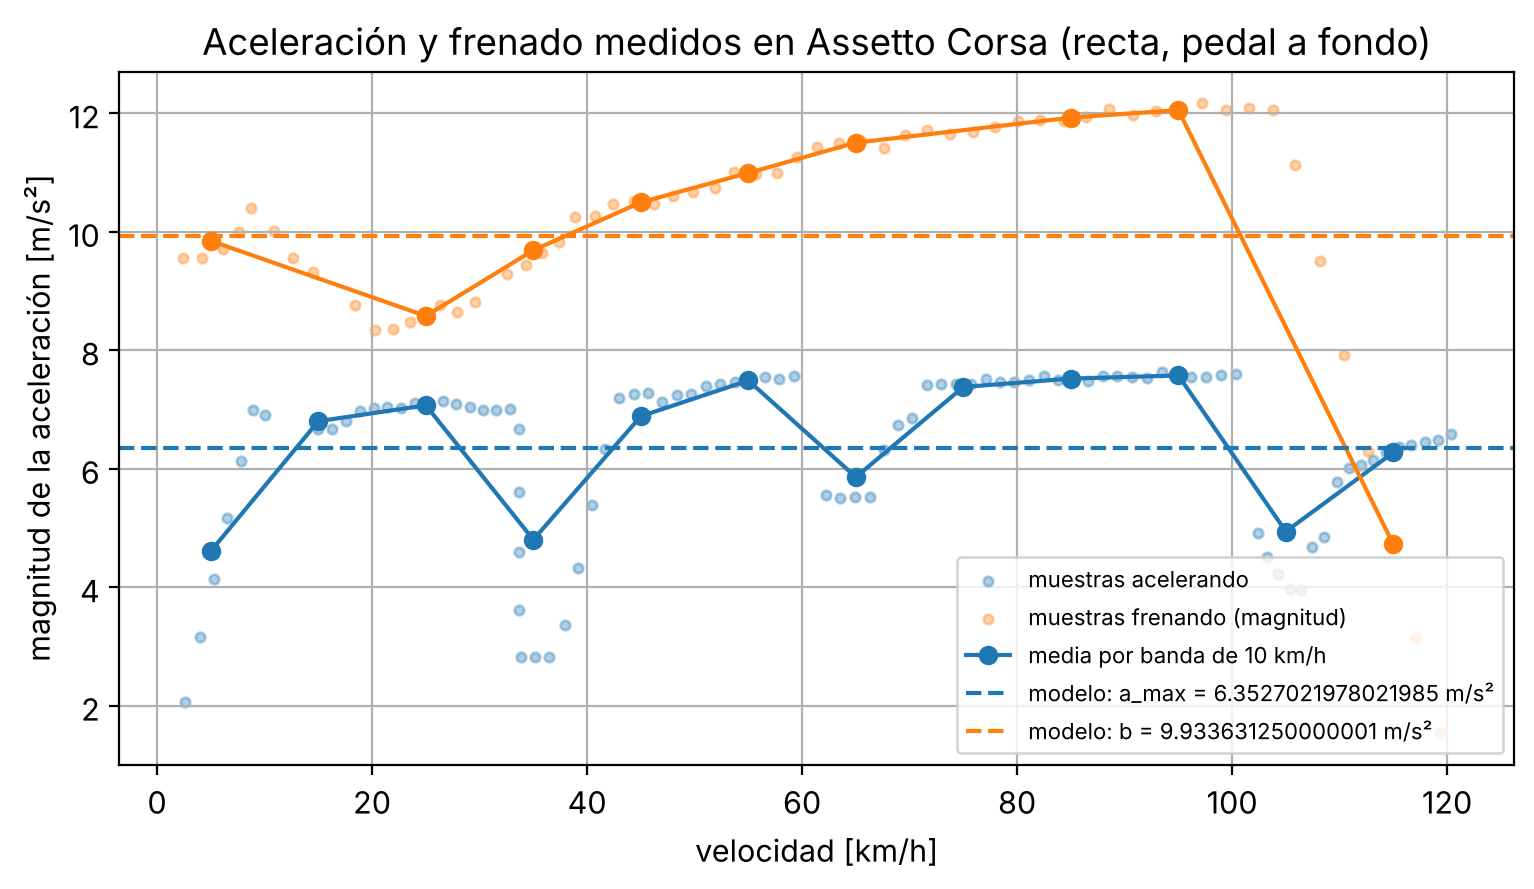

In [5]:
carpetas = sorted((CODIGO / "medicion_ac_vjoy").glob("*/muestras.csv"))
archivo_muestras = carpetas[-1]
datos_m = np.genfromtxt(archivo_muestras, delimiter=",", names=True, dtype=None, encoding="utf-8-sig")
v_kmh = datos_m["velocidad_kmh"].astype(float)
a_med = datos_m["aceleracion_firmada_m_s2"].astype(float)
tipo = datos_m["tipo"].astype(str)
acel, fren = tipo == "acelerando", tipo == "frenando"
print(f"Archivo: {archivo_muestras.relative_to(RAIZ)}")
print(f"Muestras totales: {len(tipo)} | acelerando: {acel.sum()} | frenando: {fren.sum()}")
print(f"Aceleración media medida: {a_med[acel].mean():.2f} m/s²  (mediana {np.median(a_med[acel]):.2f})")
print(f"Frenado medio medido:     {-a_med[fren].mean():.2f} m/s²  (mediana {np.median(-a_med[fren]):.2f})")

from leer_parametros_ac import limites_experimentales
a_cal, b_cal = limites_experimentales("jw_porsche_991.2_gt2_rs_us", "Hypercar road (HR)")
print(f"Calibración del programa (promedio ponderado por muestras de cada banda): a_max = {a_cal:.4f} m/s², b = {b_cal:.4f} m/s²")

# Promedio por bandas de 10 km/h, como en medir_aceleracion_frenado_ac.py
bandas = np.arange(0, 130, 10)
def por_banda(mascara, signo):
    centros, medias = [], []
    for lo in bandas:
        sel = mascara & (v_kmh >= lo) & (v_kmh < lo + 10)
        if sel.sum() >= 5:
            centros.append(lo + 5); medias.append(np.mean(signo * a_med[sel]))
    return np.array(centros), np.array(medias)
vb_a, ab = por_banda(acel, 1); vb_f, fb = por_banda(fren, -1)

plt.scatter(v_kmh[acel], a_med[acel], s=12, alpha=0.35, label="muestras acelerando")
plt.scatter(v_kmh[fren], -a_med[fren], s=12, alpha=0.35, label="muestras frenando (magnitud)")
plt.plot(vb_a, ab, "o-", c="C0", label="media por banda de 10 km/h")
plt.plot(vb_f, fb, "o-", c="C1")
plt.axhline(veh.aceleracion_max_m_s2, c="C0", ls="--", label=f"modelo: a_max = {veh.aceleracion_max_m_s2} m/s²")
plt.axhline(veh.frenado_max_m_s2, c="C1", ls="--", label=f"modelo: b = {veh.frenado_max_m_s2} m/s²")
plt.xlabel("velocidad [km/h]"); plt.ylabel("magnitud de la aceleración [m/s²]")
plt.title("Aceleración y frenado medidos en Assetto Corsa (recta, pedal a fondo)")
plt.legend(fontsize=8, loc="lower right"); plt.show()

**Interpretación.** 
- **Aceleración.** Hasta unos 100 km/h la aceleración medida es casi constante, alrededor de $6$–$7{,}5$ m/s². Si mandara la potencia, debería caer como $1/v$; como no cae, en este rango el auto está **limitado por tracción**, no por el motor. Por eso tiene sentido usar un tope constante $a_{max}$: el programa toma $6{,}35$ m/s², el promedio de las bandas ponderado por su número de muestras (`limites_experimentales` en `leer_parametros_ac.py`), y hace lo mismo con el frenado ($9{,}93$ m/s²).
- **Frenado.** La desaceleración medida **crece con la velocidad**, de unos $9$ m/s² a baja velocidad hasta unos $12$ m/s² cerca de 95 km/h. Nuestro modelo supone $b$ constante, así que no puede explicar esto. La causa física más probable es la aerodinámica, que omitimos: la carga aerodinámica empuja el auto contra el piso (más agarre) y el arrastre ayuda a frenar, y ambos efectos crecen como $v^2$.
- **Caídas de la aceleración** cerca de 35, 65 y 105 km/h: probablemente son los **cambios de marcha** de la caja automática, cuando el motor deja de empujar por un instante. Es uno de los fenómenos que omitimos (sección 2.5); en el modelo queda promediado dentro de $a_{max}$.
- **Rango de la prueba.** La medición llegó hasta unos 121 km/h, pero en la vuelta el auto pasa de 180 km/h. Usar los mismos valores constantes a mayor velocidad es una extrapolación, no un dato medido.
- **Banda de 115 km/h.** Tiene pocas muestras y un valor mucho menor; probablemente corresponde al instante en que empieza la frenada (el pedal aún no llegó a fondo), así que no la usamos para conclusiones.

**¿Cuánto cambia la distancia de frenado?** Con $b$ constante, $d = v_0^2/(2b)$. Con la desaceleración medida $b(v)$, que depende de la velocidad, hay que integrar: como $v\,dv = -b(v)\,ds$,

$$d = \int_0^{v_0} \frac{v}{b(v)}\,dv$$

Calculamos la integral con la regla del trapecio usando las medias por banda (interpoladas entre bandas).

In [6]:
v0 = 100 / 3.6
v = np.linspace(0.5, v0, 400)
b_v = np.interp(v * 3.6, vb_f[vb_f <= 100], fb[vb_f <= 100])   # bandas confiables (≤ 100 km/h)
d_medida = np.trapezoid(v / b_v, v) if hasattr(np, "trapezoid") else np.trapz(v / b_v, v)
d_modelo = mf.distancia_frenado(v0, 0.0, veh.frenado_max_m_s2)
print(f"Distancia de frenado 100 → 0 km/h con b constante del modelo ({veh.frenado_max_m_s2:.2f} m/s²): {d_modelo:.1f} m")
print(f"Distancia de frenado 100 → 0 km/h con b(v) medido en Assetto Corsa:          {d_medida:.1f} m")
print(f"Diferencia: {d_modelo - d_medida:+.1f} m ({100*(d_modelo - d_medida)/d_medida:+.0f} %)")

a_v = a_med[acel & (v_kmh > 60)] * v_kmh[acel & (v_kmh > 60)] / 3.6
print(f"\nCota inferior de potencia por masa a partir de las muestras sobre 60 km/h: P/m ≥ a·v ≈ {np.percentile(a_v, 90):.0f} W/kg")
print(f"Potencia por masa usada por el modelo: {veh.potencia_util_w/veh.masa_kg:.0f} W/kg")
if veh.potencia_util_w / veh.masa_kg < np.percentile(a_v, 90):
    print("⚠ La potencia por masa del modelo es menor que la que exigen las mediciones: "
          "con estos parámetros el modelo acelera menos en recta que el auto en Assetto Corsa.")

Distancia de frenado 100 → 0 km/h con b constante del modelo (9.93 m/s²): 38.8 m
Distancia de frenado 100 → 0 km/h con b(v) medido en Assetto Corsa:          34.7 m
Diferencia: +4.1 m (+12 %)

Cota inferior de potencia por masa a partir de las muestras sobre 60 km/h: P/m ≥ a·v ≈ 208 W/kg
Potencia por masa usada por el modelo: 327 W/kg


**Interpretación.** Con la desaceleración medida, el auto frena en menos distancia que la que supone el modelo: **el modelo es conservador al frenar**, empieza a frenar antes de lo estrictamente necesario. Es preferible a lo contrario (frenar tarde significa salirse). La segunda cifra sirve de control de calidad de los parámetros: si la potencia por masa del modelo queda por debajo de la cota que exigen las mediciones, el modelo subestimaría la aceleración en recta y habría que revisar `potencia_util_w`.

## 5. Geometría del circuito

**De dónde sale la pista.** Las pistas de Assetto Corsa traen dos archivos, `data/side_l.csv` y `data/side_r.csv`, con puntos de los bordes izquierdo y derecho. Cada fila tiene las coordenadas $(X, Y_{altura}, Z)$ y el progreso de vuelta (de 0 a 1). `geometria_circuito.py` hace lo siguiente:

1. Toma $X$ y $Z$ (ignora la altura: modelo 2D) y cambia el signo de $Z$ para que el sistema de ejes coincida con el de la telemetría.
2. Interpola ambos bordes sobre los mismos 1500 valores de progreso, para emparejar cada punto izquierdo con uno derecho.
3. La línea central es el punto medio de cada par, y el ancho local es la distancia entre ellos.

Luego `gestor_circuito.py` suaviza los tres trazados con un filtro $(p_{i-1} + 2p_i + p_{i+1})/4$ (sin moverlos más de 1 m), y el programa corta una vuelta completa con 200 m de margen antes del auto y 650 m después.

**Qué geometría usa el notebook**, en este orden:

1. `plan_compartido.json`: la geometría de Tocancipá **ya preparada** por el programa en vivo (orientada, suavizada y con márgenes), y la posición real de salida del auto.
2. `datos/side_l.csv` y `datos/side_r.csv`: los bordes del mod; el notebook los prepara igual que el programa en vivo.
3. Si no hay ninguno, un **circuito de prueba** cerrado de unos 2 km y 11 m de ancho, para que el notebook se ejecute de principio a fin.


Pista: Tocancipá (plan_compartido.json del programa en vivo)
Vuelta de 2674 m (entre s = 202 m y s = 2875 m de la geometría extendida de 3525 m)
Puntos por vuelta: 1500 | ancho entre 9.0 y 14.5 m | radio mínimo: 29.0 m


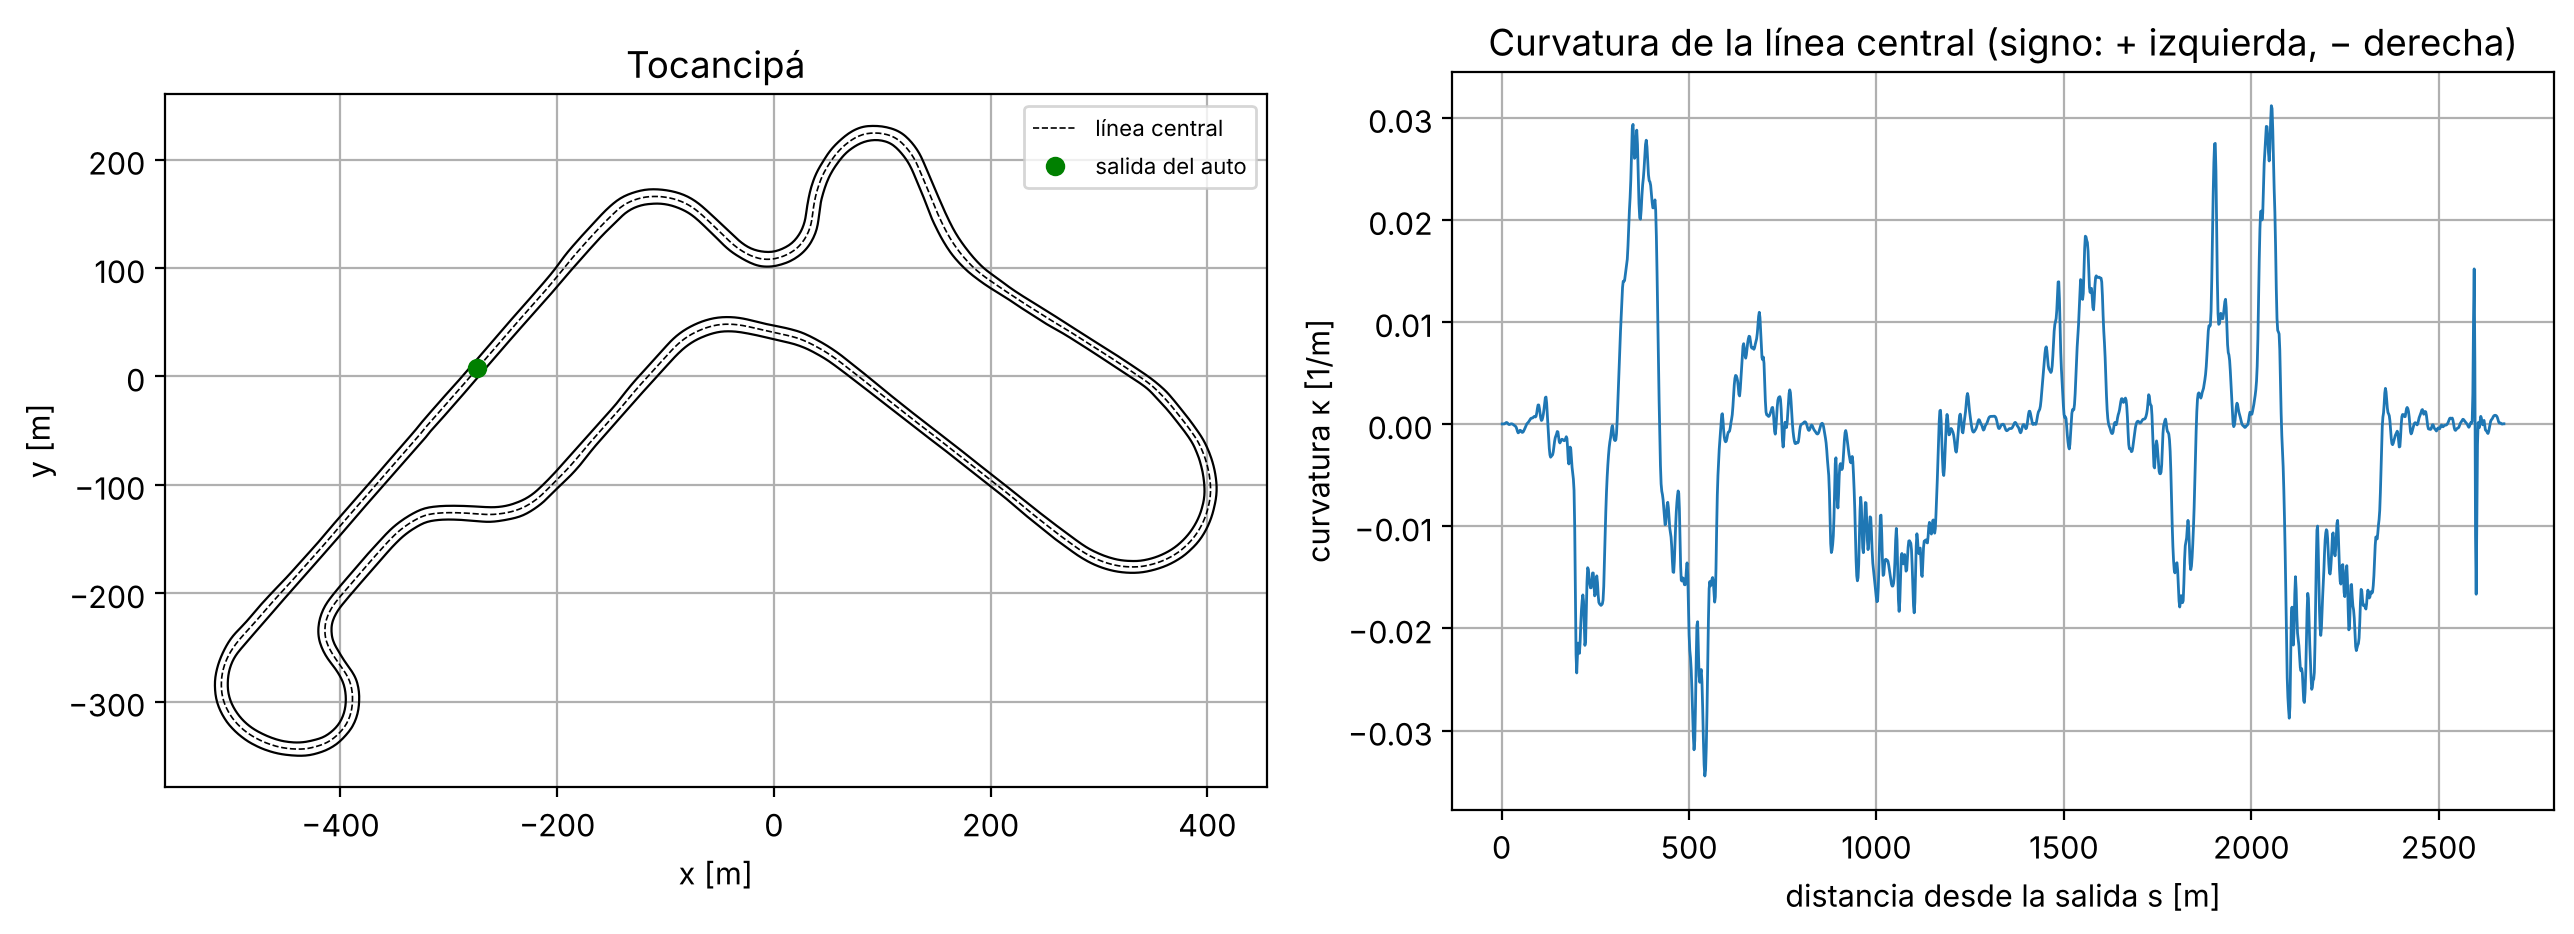

In [7]:
def circuito_de_prueba(n=1500, ancho=11.0):
    # Circuito cerrado y suave: curva Catmull-Rom por puntos de control [m], filtrada con Fourier
    P = np.array([[0, 0], [350, 0], [520, 20], [560, 110], [500, 190], [380, 200], [300, 260],
                  [320, 360], [250, 430], [100, 420], [60, 330], [120, 250], [60, 170],
                  [-60, 150], [-110, 80], [-95, 25]], float)
    t = np.linspace(0, 1, 600, endpoint=False)[:, None]
    tramos = []
    for i in range(len(P)):
        p0, p1, p2, p3 = P[i - 1], P[i], P[(i + 1) % len(P)], P[(i + 2) % len(P)]
        tramos.append(0.5 * (2*p1 + (-p0 + p2)*t + (2*p0 - 5*p1 + 4*p2 - p3)*t**2 + (-p0 + 3*p1 - 3*p2 + p3)*t**3))
    xy = np.vstack(tramos)
    z = np.fft.fft(xy[:, 0] + 1j * xy[:, 1])            # quita los quiebres de curvatura entre tramos
    z[np.abs(np.fft.fftfreq(len(z), 1 / len(z))) > 30] = 0
    z = np.fft.ifft(z)
    xy = np.column_stack([z.real, z.imag])
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(np.vstack([xy, xy[:1]]), axis=0), axis=1))]
    s = np.linspace(0, d[-1], n, endpoint=False)
    xy_c = np.vstack([xy, xy[:1]])
    c = np.column_stack([np.interp(s, d, xy_c[:, 0]), np.interp(s, d, xy_c[:, 1])])
    tang = np.roll(c, -1, 0) - np.roll(c, 1, 0)
    tang /= np.linalg.norm(tang, axis=1)[:, None]
    normal = np.column_stack([-tang[:, 1], tang[:, 0]])
    izq, der = c + ancho / 2 * normal, c - ancho / 2 * normal
    return geo.GeometriaCircuito(izq, der, c, s / d[-1], np.linalg.norm(izq - der, axis=1))

def preparar_como_en_vivo(geometria):
    # Mismos pasos que conducir_fisica_optimizado.main(); el auto sale al final de la zona más recta
    centro = geometria.centro
    k = np.abs(mf.curvaturas_de_puntos(np.vstack([centro[-1:], centro, centro[:1]]))[1:-1])
    paso = np.linalg.norm(np.diff(np.vstack([centro, centro[:1]]), axis=0), axis=1).mean()
    ventana = int(250 / paso)
    peor_atras = np.array([k[(i - np.arange(ventana)) % len(k)].max() for i in range(len(k))])
    i = int(np.argmin(peor_atras))
    tang = centro[(i + 1) % len(centro)] - centro[i]
    auto = mf.Estado(*centro[i], float(np.arctan2(tang[1], tang[0])), 0.0)
    c, iz, de = cfo.orientar(geometria, auto)
    c, iz, de = gc.suavizar_geometria(c, iz, de)
    c, iz, de, longitud, _ = gc.preparar_vuelta(c, iz, de, np.array([auto.x, auto.y]),
                                                 margen_atras_m=200.0, margen_despues_m=650.0)
    mantener = np.r_[True, np.linalg.norm(np.diff(c, axis=0), axis=1) > 1e-5]
    c, iz, de = c[mantener], iz[mantener], de[mantener]
    s_inicio, _ = cfo.progreso([auto.x, auto.y], c, cfo.estaciones(c))
    return c, iz, de, s_inicio, s_inicio + longitud, auto

lado_izq, lado_der = DATOS / "side_l.csv", DATOS / "side_r.csv"
if PLAN is not None:
    c, iz, de = (np.asarray(PLAN[k], float) for k in ("centro", "izquierdo", "derecho"))
    S_INICIO, S_META = float(PLAN["s_inicio"]), float(PLAN["s_fin"])
    x0, y0 = (float(np.interp(S_INICIO, cfo.estaciones(c), c[:, j])) for j in (0, 1))
    i0 = int(np.searchsorted(cfo.estaciones(c), S_INICIO))
    auto0 = mf.Estado(x0, y0, float(np.arctan2(*(c[i0 + 1] - c[i0])[::-1])), 0.0)
    PISTA = "Tocancipá (plan_compartido.json del programa en vivo)"
elif lado_izq.exists() and lado_der.exists():
    progreso = np.linspace(0.0, 1.0, geo.NUM_PUNTOS, endpoint=False)
    b_izq = geo.interpolar_borde(geo.cargar_csv(lado_izq, geo.SIGNO_Z_CSV), progreso)
    b_der = geo.interpolar_borde(geo.cargar_csv(lado_der, geo.SIGNO_Z_CSV), progreso)
    geometria = geo.GeometriaCircuito(b_izq, b_der, (b_izq + b_der) / 2, progreso, np.linalg.norm(b_der - b_izq, axis=1))
    c, iz, de, S_INICIO, S_META, auto0 = preparar_como_en_vivo(geometria)
    PISTA = "Tocancipá (bordes side_l.csv y side_r.csv del mod)"
else:
    c, iz, de, S_INICIO, S_META, auto0 = preparar_como_en_vivo(circuito_de_prueba())
    PISTA = "circuito de prueba (falta plan_compartido.json)"

s_c = cfo.estaciones(c)
LONGITUD = S_META - S_INICIO
vuelta = (s_c >= S_INICIO) & (s_c <= S_META)
k_vuelta = mf.curvaturas_de_puntos(c[vuelta])
anchos = np.linalg.norm(iz - de, axis=1)[vuelta]
print(f"\nPista: {PISTA}")
print(f"Vuelta de {LONGITUD:.0f} m (entre s = {S_INICIO:.0f} m y s = {S_META:.0f} m de la geometría extendida de {s_c[-1]:.0f} m)")
print(f"Puntos por vuelta: {vuelta.sum()} | ancho entre {anchos.min():.1f} y {anchos.max():.1f} m | radio mínimo: {1/np.abs(k_vuelta).max():.1f} m")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.plot(*iz[vuelta].T, "k-", lw=0.8); a1.plot(*de[vuelta].T, "k-", lw=0.8)
a1.plot(*c[vuelta].T, "k--", lw=0.6, label="línea central"); a1.plot(auto0.x, auto0.y, "go", label="salida del auto")
a1.set_aspect("equal"); a1.set(xlabel="x [m]", ylabel="y [m]", title=PISTA.split(" (")[0]); a1.legend(fontsize=8)
a2.plot(s_c[vuelta] - S_INICIO, k_vuelta, lw=1)
a2.set(xlabel="distancia desde la salida s [m]", ylabel="curvatura κ [1/m]",
       title="Curvatura de la línea central (signo: + izquierda, − derecha)")
plt.tight_layout(); plt.show()

**Interpretación.** La curvatura es casi cero en las rectas y forma picos en las curvas; la altura de cada pico es $1/R$. Las curvas con mayor $|\kappa|$ son las que obligan a ir más lento, porque $v_{max} = \sqrt{\mu g/|\kappa|}$. Como la curvatura sale de diferencias entre puntos cercanos, es sensible al ruido de los datos; por eso el programa suaviza la geometría (lo movió apenas centímetros) antes de usarla.

La geometría extendida incluye la vuelta más los márgenes: el de atrás da al perfil una entrada desde antes del auto y el de adelante evita que el evaluador frene a cero al final de la vuelta. El auto sale al final de una recta porque el evaluador supone que el plan empieza en recta (lo dice su documentación): arrancar dentro de una curva no deja acelerar en el primer tramo.

### 5.1 La pista como integral de su curvatura

Comprobamos la primera integración de la sección 2.3: tomamos solo la curvatura $\kappa(s)$ de la vuelta y la integramos con `integrar_pista_desde_curvatura_paper` para reconstruir la pista. Si la geometría y la integración son coherentes:

- la orientación total de una vuelta cerrada debe ser $\int \kappa\,ds = \pm 360°$;
- la pista reconstruida debe parecerse a la original, con un error de posición que crece a lo largo de la vuelta, porque cada pequeño error de $\kappa$ se acumula primero en el rumbo y después en la posición.

Separación media entre puntos: 1.78 m (desviación 0.054 m)
Giro total de la vuelta: ∫κ ds = -359.9°
Error de posición de la pista reconstruida: medio 12.2 m, al final 22.8 m (0.9 % de la longitud de la vuelta)


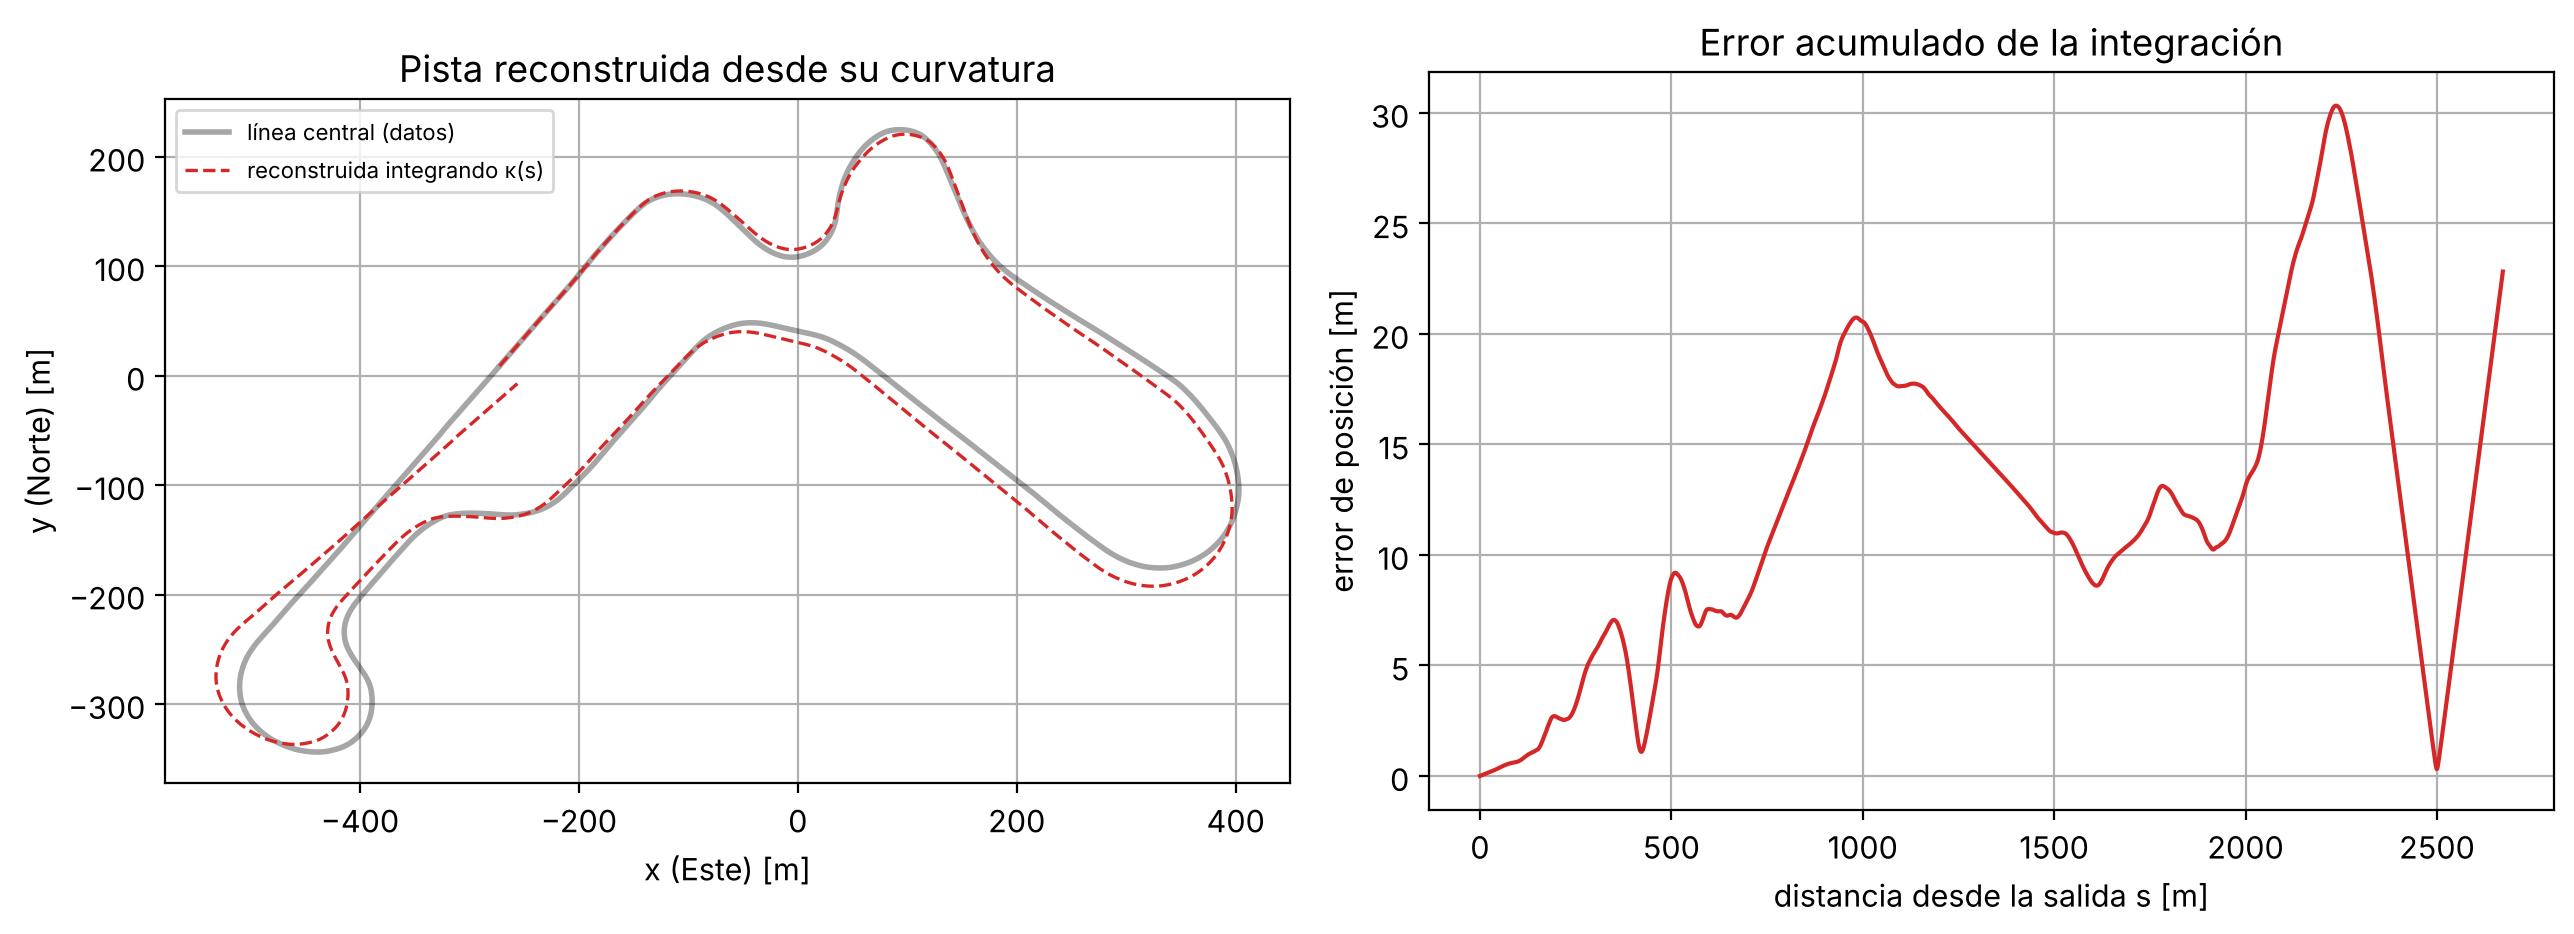

In [8]:
c_vuelta = c[vuelta]
s_vuelta = cfo.estaciones(c_vuelta)
ds_medio = float(np.diff(s_vuelta).mean())
k_v = mf.curvaturas_de_puntos(c_vuelta)
t0 = c_vuelta[1] - c_vuelta[0]
psi_r0 = np.arctan2(-t0[0], t0[1])          # rumbo inicial medido desde el norte (convención del artículo)
reconstruida, psi_r = mf.integrar_pista_desde_curvatura_paper(k_v[:-1], ds_m=ds_medio, este_inicial=c_vuelta[0, 0],
                                                              norte_inicial=c_vuelta[0, 1], psi_inicial_rad=psi_r0)
error = np.linalg.norm(reconstruida - c_vuelta, axis=1)
print(f"Separación media entre puntos: {ds_medio:.2f} m (desviación {np.diff(s_vuelta).std():.3f} m)")
print(f"Giro total de la vuelta: ∫κ ds = {np.degrees(np.sum(k_v[:-1] * np.diff(s_vuelta))):.1f}°")
print(f"Error de posición de la pista reconstruida: medio {error.mean():.1f} m, al final {error[-1]:.1f} m "
      f"({100*error[-1]/s_vuelta[-1]:.1f} % de la longitud de la vuelta)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.plot(*c_vuelta.T, "k-", lw=2, alpha=0.35, label="línea central (datos)")
a1.plot(*reconstruida.T, "C3--", lw=1.2, label="reconstruida integrando κ(s)")
a1.set_aspect("equal"); a1.set(xlabel="x (Este) [m]", ylabel="y (Norte) [m]", title="Pista reconstruida desde su curvatura"); a1.legend(fontsize=8)
a2.plot(s_vuelta, error, c="C3")
a2.set(xlabel="distancia desde la salida s [m]", ylabel="error de posición [m]", title="Error acumulado de la integración")
plt.tight_layout(); plt.show()

**Interpretación.** El giro total da prácticamente $\pm 360°$: la integral de la curvatura cierra la vuelta, así que la curvatura que usa el modelo es coherente con la forma real del circuito (el signo solo indica el sentido de giro). La posición reconstruida sigue la forma de la pista, pero se va separando a lo largo de la vuelta. Es el comportamiento típico de integrar dos veces: un error pequeño y sistemático en $\kappa$ (ruido de los datos, curvatura constante supuesta en cada tramo, separación media en vez de la real) se acumula en el rumbo y luego en la posición. Por eso el programa no reconstruye la pista desde $\kappa$ para conducir: usa los puntos medidos y deja la integración de la curvatura para estimar ángulos de dirección y velocidades.

## 6. Perfil de velocidad y trayectoria optimizada

### 6.1 Cómo se calcula el perfil (`estimaciones.evaluar_trayectoria`)

1. **Límite por curvatura** en cada punto: $v_{lim,i} = \min\big(\sqrt{\mu g/|\kappa_i|},\ v_{tope}\big)$.
2. **Pasada hacia atrás (frenado).** Recorriendo la pista de atrás hacia adelante, cada punto no puede ir más rápido de lo que permite frenar hasta el siguiente: $v_i \le \sqrt{v_{i+1}^2 + 2b\,\Delta s_i}$, con $b$ limitado por los frenos y por el agarre que sobra después de girar.
3. **Pasada hacia adelante (aceleración).** Cada punto no puede ir más rápido de lo que el motor y el agarre restante permiten acelerar desde el anterior: $v_{i+1} \le \sqrt{v_i^2 + 2a\,\Delta s_i}$, con $a = \min(a_{motor}, a_{disp})$.
4. Como el agarre disponible depende de la propia velocidad, las dos pasadas se repiten hasta que el perfil deja de cambiar (máximo 30 iteraciones).
5. El tiempo es $T = \sum 2\Delta s_i/(v_i + v_{i+1})$.

### 6.2 Ápices definidos geométricamente

Antes de optimizar, el programa encuentra las curvas solo con geometría: suaviza la curvatura con un promedio móvil de 21 puntos, marca como curva todo tramo con $|\kappa| \ge 0{,}005$ 1/m (radio menor que 200 m) de al menos 8 puntos, y define el **ápice** de cada curva como el punto de mayor $|\kappa|$ suavizada. Se quedan hasta 20 ápices, separados al menos 35 m entre sí. El signo de $\kappa$ en el ápice dice hacia qué lado curva y, por tanto, cuál es el borde interior.

### 6.3 Cómo se optimiza la trayectoria (`conducir_fisica_optimizado.optimizar`)

Se desplaza la línea central una distancia $d(s)$ en la dirección normal, $\mathbf{P}(s) = \mathbf{C}(s) + d(s)\,\mathbf{N}(s)$. En cada curva detectada se prueban 36 deformaciones de la forma **exterior → interior → exterior**, combinando: ápice temprano, medio o tardío; qué tanto se acerca al borde interior (85, 95 o 99 % del espacio disponible) y al exterior (70 o 95 %); y la longitud de la maniobra (85 o 130 m). Los tramos se unen con el polinomio quíntico $q(t) = t^3(10 - 15t + 6t^2)$, que tiene primera y segunda derivada nulas en los extremos, así que la curvatura no salta. Una candidata se acepta solo si **reduce el tiempo de toda la vuelta** al menos 0,02 s y si **las cuatro esquinas de la huella** quedan dentro de los bordes. El proceso se repite 3 veces sobre todas las curvas.

La siguiente celda marca los ápices con el mismo criterio del programa y después ejecuta exactamente la función de optimización (tarda unos segundos).

In [9]:
# B1 de optimizar(): curvas y ápices por geometría (mismos umbrales del programa)
k_c = mf.curvaturas_de_puntos(c)
k_suave = np.convolve(k_c, np.ones(21) / 21, mode="same")
grupos, actual = [], []
for i, activo in enumerate(np.abs(k_suave) >= cfo.UMBRAL_CURVA):
    if activo:
        actual.append(i)
    elif actual:
        if len(actual) >= 8: grupos.append(actual)
        actual = []
picos = sorted((max(g, key=lambda j: abs(k_suave[j])) for g in grupos), key=lambda j: -abs(k_suave[j]))
apices = []
for i in picos:
    if S_INICIO + 165 < s_c[i] < S_META - 165 and all(abs(s_c[i] - s_c[j]) >= 35 for j in apices):
        apices.append(i)
apices = sorted(apices[:cfo.MAX_CURVAS])
print(f"Ápices encontrados: {len(apices)}")
for n, i in enumerate(apices, 1):
    print(f"  curva {n:2d}: s = {s_c[i] - S_INICIO:6.0f} m | radio = {1/abs(k_suave[i]):5.0f} m | "
          f"{'izquierda' if k_suave[i] > 0 else 'derecha'} | v_max = {3.6*mf.velocidad_maxima_curva(k_suave[i], veh):4.0f} km/h")

Ápices encontrados: 12
  curva  1: s =    215 m | radio =    52 m | derecha | v_max =   90 km/h
  curva  2: s =    368 m | radio =    39 m | izquierda | v_max =   78 km/h
  curva  3: s =    529 m | radio =    36 m | derecha | v_max =   75 km/h
  curva  4: s =    675 m | radio =   118 m | izquierda | v_max =  136 km/h
  curva  5: s =    890 m | radio =   138 m | derecha | v_max =  147 km/h
  curva  6: s =   1046 m | radio =    69 m | derecha | v_max =  104 km/h
  curva  7: s =   1472 m | radio =   118 m | izquierda | v_max =  136 km/h
  curva  8: s =   1572 m | radio =    68 m | izquierda | v_max =  103 km/h
  curva  9: s =   1809 m | radio =    68 m | derecha | v_max =  103 km/h
  curva 10: s =   1913 m | radio =    65 m | izquierda | v_max =  101 km/h
  curva 11: s =   2044 m | radio =    39 m | izquierda | v_max =   78 km/h
  curva 12: s =   2150 m | radio =    43 m | derecha | v_max =   82 km/h


In [10]:
evaluacion_centro = est.evaluar_trayectoria(c, veh, velocidad_entrada_m_s=0.0, tope_velocidad_m_s=cfo.TOPE_EVALUADOR_M_S)
ruta, evaluacion = cfo.optimizar(c, iz, de, veh, 0.0, S_INICIO, S_META)

Curvas propuestas: 12


Pasada 1, curva 2: medio | interior=85%, exterior=70%, extensión=130 m | T_vuelta=94.774 s


Pasada 1, curva 8: medio | interior=85%, exterior=70%, extensión=130 m | T_vuelta=94.435 s


Pasada 1, curva 9: tardio | interior=95%, exterior=70%, extensión=130 m | T_vuelta=93.985 s


Pasada 1, curva 10: temprano | interior=95%, exterior=70%, extensión=130 m | T_vuelta=93.814 s


Pasada 1, curva 11: medio | interior=99%, exterior=70%, extensión=85 m | T_vuelta=93.384 s


Pasada 1, curva 12: temprano | interior=85%, exterior=70%, extensión=130 m | T_vuelta=93.171 s


Pasada 2, curva 8: medio | interior=85%, exterior=95%, extensión=130 m | T_vuelta=93.134 s


Evaluaciones físicas: 1192; mejoras aceptadas: 7; rechazos por huella: 0
Centro (vuelta): 94.942 s | Optimizada (vuelta): 93.134 s | Ganancia de vuelta: 1.809 s
Desplazamiento lateral máximo: 4.904 m


Tiempo de vuelta predicho por la línea central:      94.94 s
Tiempo de vuelta predicho por la ruta optimizada:    93.13 s  (ganancia 1.81 s)
Velocidad máxima del plan: 198 km/h | mínima en vuelta: 67 km/h
Uso máximo del agarre lateral: 100 %
Tiempo de vuelta del plan que se usó en vivo (plan_compartido.json): 93.13 s | recalculado en este notebook: 93.13 s


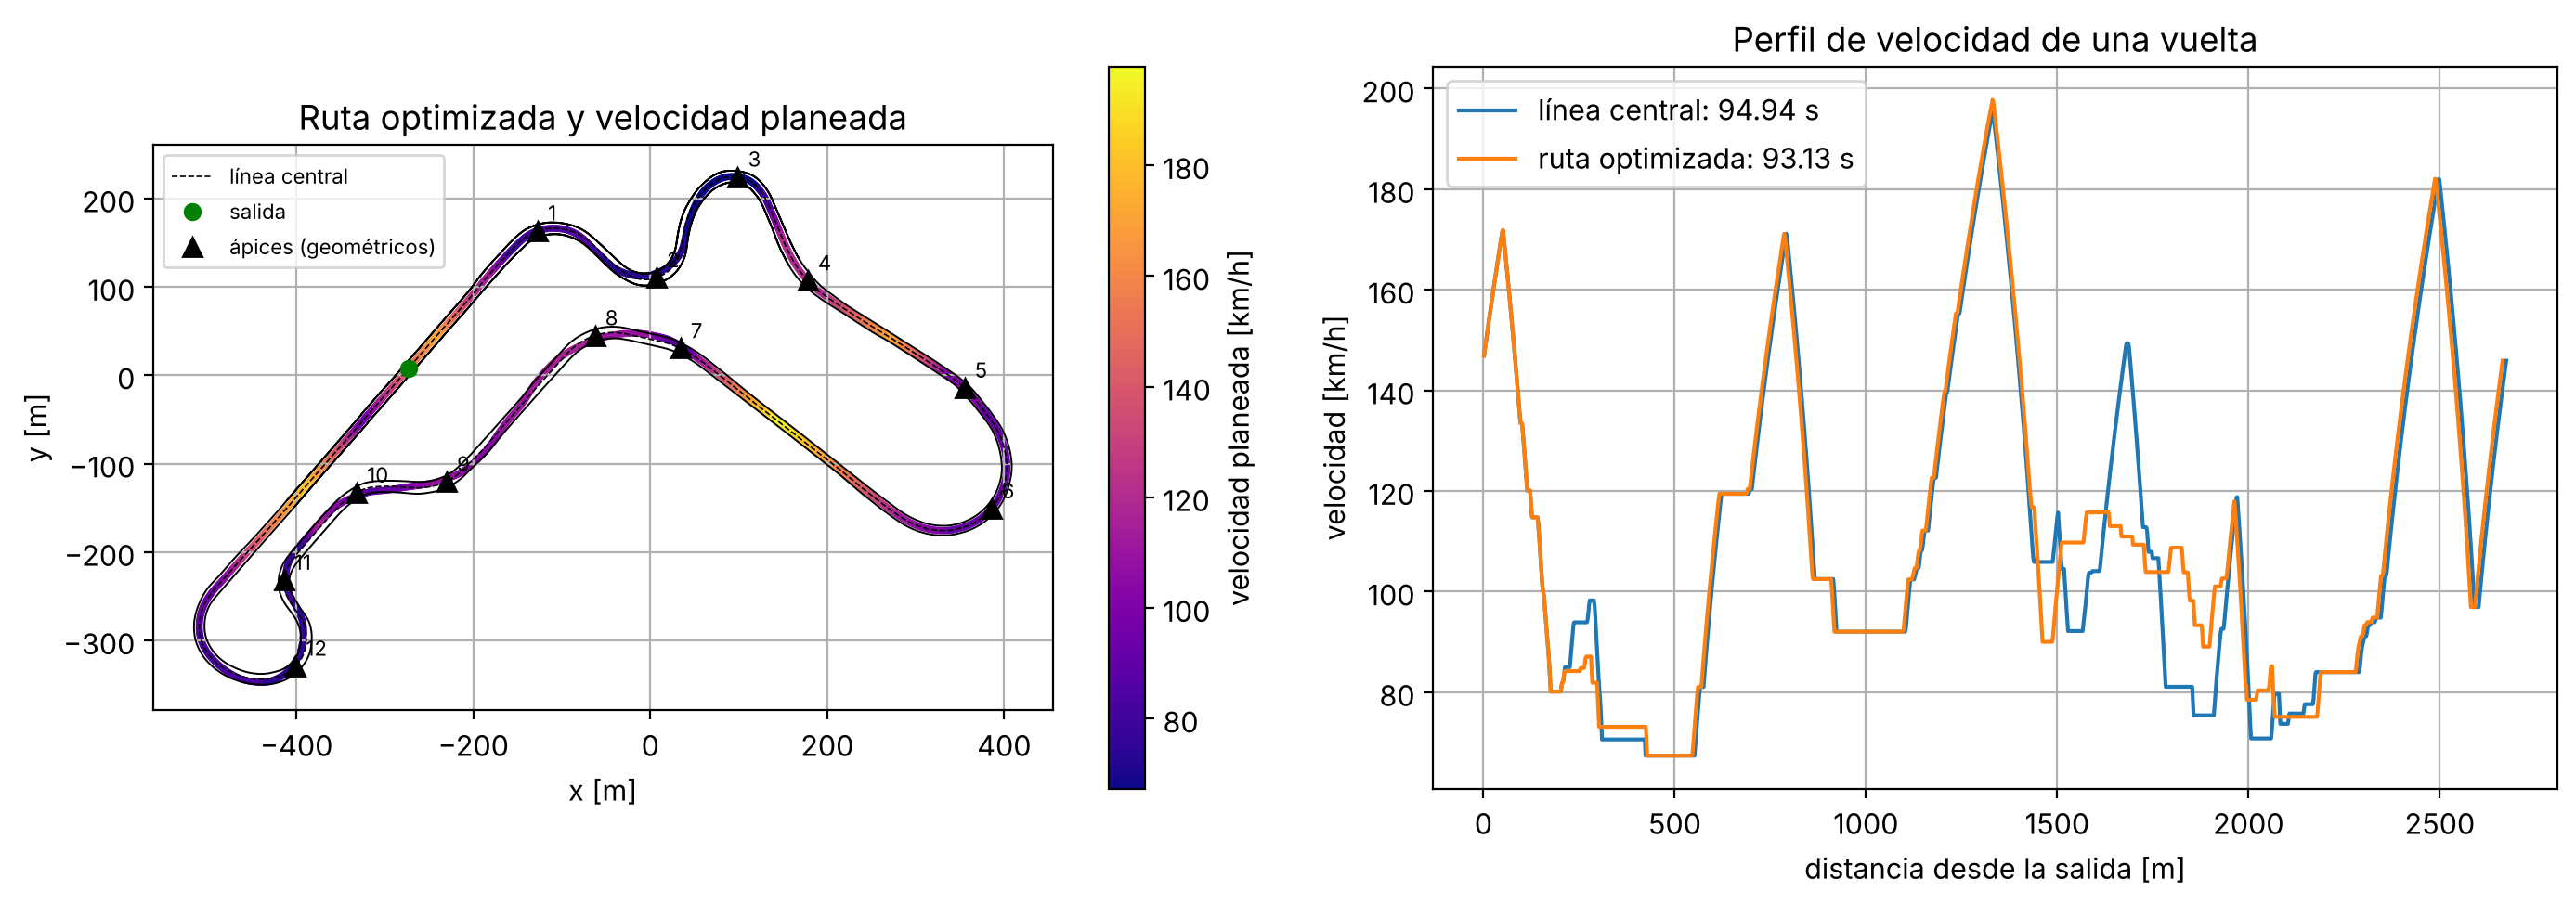

In [11]:
from types import SimpleNamespace
def tiempo_vuelta(puntos, v):
    # Tiempo entre salida y meta con la función del programa: T = Σ 2Δs/(v_i + v_{i+1})
    return cfo.tiempo_vuelta_plan(puntos, SimpleNamespace(velocidades_m_s=v), s_c, S_INICIO, S_META)

s_r = cfo.estaciones(ruta)
S_INICIO_R, S_META_R = np.interp([S_INICIO, S_META], s_c, s_r)
T_centro = tiempo_vuelta(c, evaluacion_centro.velocidades_m_s)
T_plan = tiempo_vuelta(ruta, evaluacion.velocidades_m_s)
print(f"Tiempo de vuelta predicho por la línea central:     {T_centro:6.2f} s")
print(f"Tiempo de vuelta predicho por la ruta optimizada:   {T_plan:6.2f} s  (ganancia {T_centro - T_plan:.2f} s)")
print(f"Velocidad máxima del plan: {evaluacion.velocidades_m_s.max()*3.6:.0f} km/h | mínima en vuelta: "
      f"{evaluacion.velocidades_m_s[(s_r > S_INICIO_R) & (s_r < S_META_R)].min()*3.6:.0f} km/h")
print(f"Uso máximo del agarre lateral: {100*evaluacion.max_uso_lateral:.0f} %")
if PLAN is not None:
    print(f"Tiempo de vuelta del plan que se usó en vivo (plan_compartido.json): {PLAN['tiempo_estimado_s']:.2f} s | "
          f"recalculado en este notebook: {T_plan:.2f} s")

vuelta_r = (s_r >= S_INICIO_R) & (s_r <= S_META_R)
vuelta_c = (s_c >= S_INICIO) & (s_c <= S_META)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.plot(*iz.T, "k-", lw=0.7); a1.plot(*de.T, "k-", lw=0.7)
a1.plot(*c[vuelta_c].T, "k--", lw=0.6, label="línea central")
sc_ = a1.scatter(*ruta[vuelta_r].T, c=evaluacion.velocidades_m_s[vuelta_r] * 3.6, s=3, cmap="plasma")
plt.colorbar(sc_, ax=a1, label="velocidad planeada [km/h]")
a1.plot(auto0.x, auto0.y, "go", label="salida")
a1.plot(*c[apices].T, "k^", ms=7, label="ápices (geométricos)")
for n, i in enumerate(apices, 1):
    a1.annotate(str(n), c[i], xytext=(4, 4), textcoords="offset points", fontsize=8)
a1.set_aspect("equal"); a1.legend(fontsize=8)
a1.set(xlabel="x [m]", ylabel="y [m]", title="Ruta optimizada y velocidad planeada")
a2.plot(s_c[vuelta_c] - S_INICIO, evaluacion_centro.velocidades_m_s[vuelta_c] * 3.6, label=f"línea central: {T_centro:.2f} s")
a2.plot(s_r[vuelta_r] - S_INICIO_R, evaluacion.velocidades_m_s[vuelta_r] * 3.6, label=f"ruta optimizada: {T_plan:.2f} s")
a2.set(xlabel="distancia desde la salida [m]", ylabel="velocidad [km/h]", title="Perfil de velocidad de una vuelta"); a2.legend()
plt.tight_layout(); plt.show()

**Interpretación.** 
- Las caídas del perfil son las curvas: antes de cada una, la pasada hacia atrás impone una rampa de frenado con pendiente fija (en $v^2$ contra $s$, una recta de pendiente $-2b$). Después, la pasada hacia adelante recupera velocidad más despacio, porque $a_{max} < b$ y porque a alta velocidad la potencia limita ($a = P/mv$).
- La ruta optimizada gana tiempo porque abre las curvas: al entrar por fuera, tocar el interior cerca del ápice y salir por fuera, el radio efectivo crece y con él $v_{max} = \sqrt{\mu g R}$. Cada candidata se juzga integrando su tiempo de vuelta: así el modelo decide si una trayectoria es mejor o peor que otra sin manejarla.
- El tiempo recalculado coincide con el del plan que se usó en vivo: el notebook ejecuta el mismo código con los mismos datos.
- **Perfil escalonado.** Dentro de algunas curvas la velocidad queda constante, por debajo del límite. La pasada hacia adelante usa el agarre disponible en el punto siguiente evaluado con su velocidad límite, donde ya no queda agarre longitudinal; entonces no deja acelerar dentro de la curva. Es un efecto del método discreto y lo hace conservador (predice tiempos algo mayores), no un fenómeno físico.

## 7. Simulación en el tiempo: el agente conduce el modelo de bicicleta

El perfil de la sección 6 es un **plan**: dice a qué velocidad conviene ir en cada punto, pero no simula el movimiento. Para comprobar que ese plan se puede seguir, cerramos el lazo dentro del notebook: el **mismo agente** que maneja el auto en Assetto Corsa (`AgenteConductor`, con la función `controlar` del programa en vivo) maneja ahora nuestro modelo de bicicleta.

**El agente conductor** es un agente de IA que sabe conducir: recibe el plan y la posición del auto, y decide volante, acelerador y freno. La diferencia con enviar las órdenes del plan directamente es que **no ejecuta cambios imposibles**: las ruedas no giran más de 30° ni más rápido que 360°/s, el acelerador y el freno no cambian más de 3 y 4 unidades por segundo, nunca acelera y frena a la vez, y si el giro real se atrasa respecto al pedido suelta el acelerador. No usa recompensas ni aprendizaje: sus reglas están programadas, no entrenadas.

En cada paso de $\Delta t = 0{,}02$ s (los mismos 50 Hz del programa en vivo):

1. Se proyecta la posición del auto sobre la ruta para saber su avance $s$ (`cfo.progreso`).
2. `controlar` toma del plan la velocidad objetivo y el ángulo de ruedas $\delta = \arctan(L\kappa)$ para ese punto.
3. El agente corrige la dirección con el error lateral $e$ y el error de orientación $e_\psi$ respecto a la ruta, $\delta = \delta_{plan} + k_e\,e + k_\psi\,e_\psi$, y calcula los pedales con un control proporcional al error de velocidad, limitando qué tan rápido cambian.
4. Como el modelo no tiene pedales, traducimos los pedales a aceleración: $a = u_{acel}\, a_{motor}(v) - u_{freno}\, b$.
5. `mf.paso_bicicleta` avanza el estado un paso con Euler.

Este gemelo digital reemplaza a Assetto Corsa por nuestro modelo; la sección 11 compara con el simulador real.

¿Completó la vuelta? True | tiempo simulado: 97.04 s (plan: 93.13 s, que asume salida lanzada)
Error lateral: máximo 3.62 m, medio 0.11 m
Pasos que superan el círculo de fricción: 5.9 %  (uso máximo: 264 %)
Instantes revisados con alguna esquina fuera de los bordes locales: 0 de 486


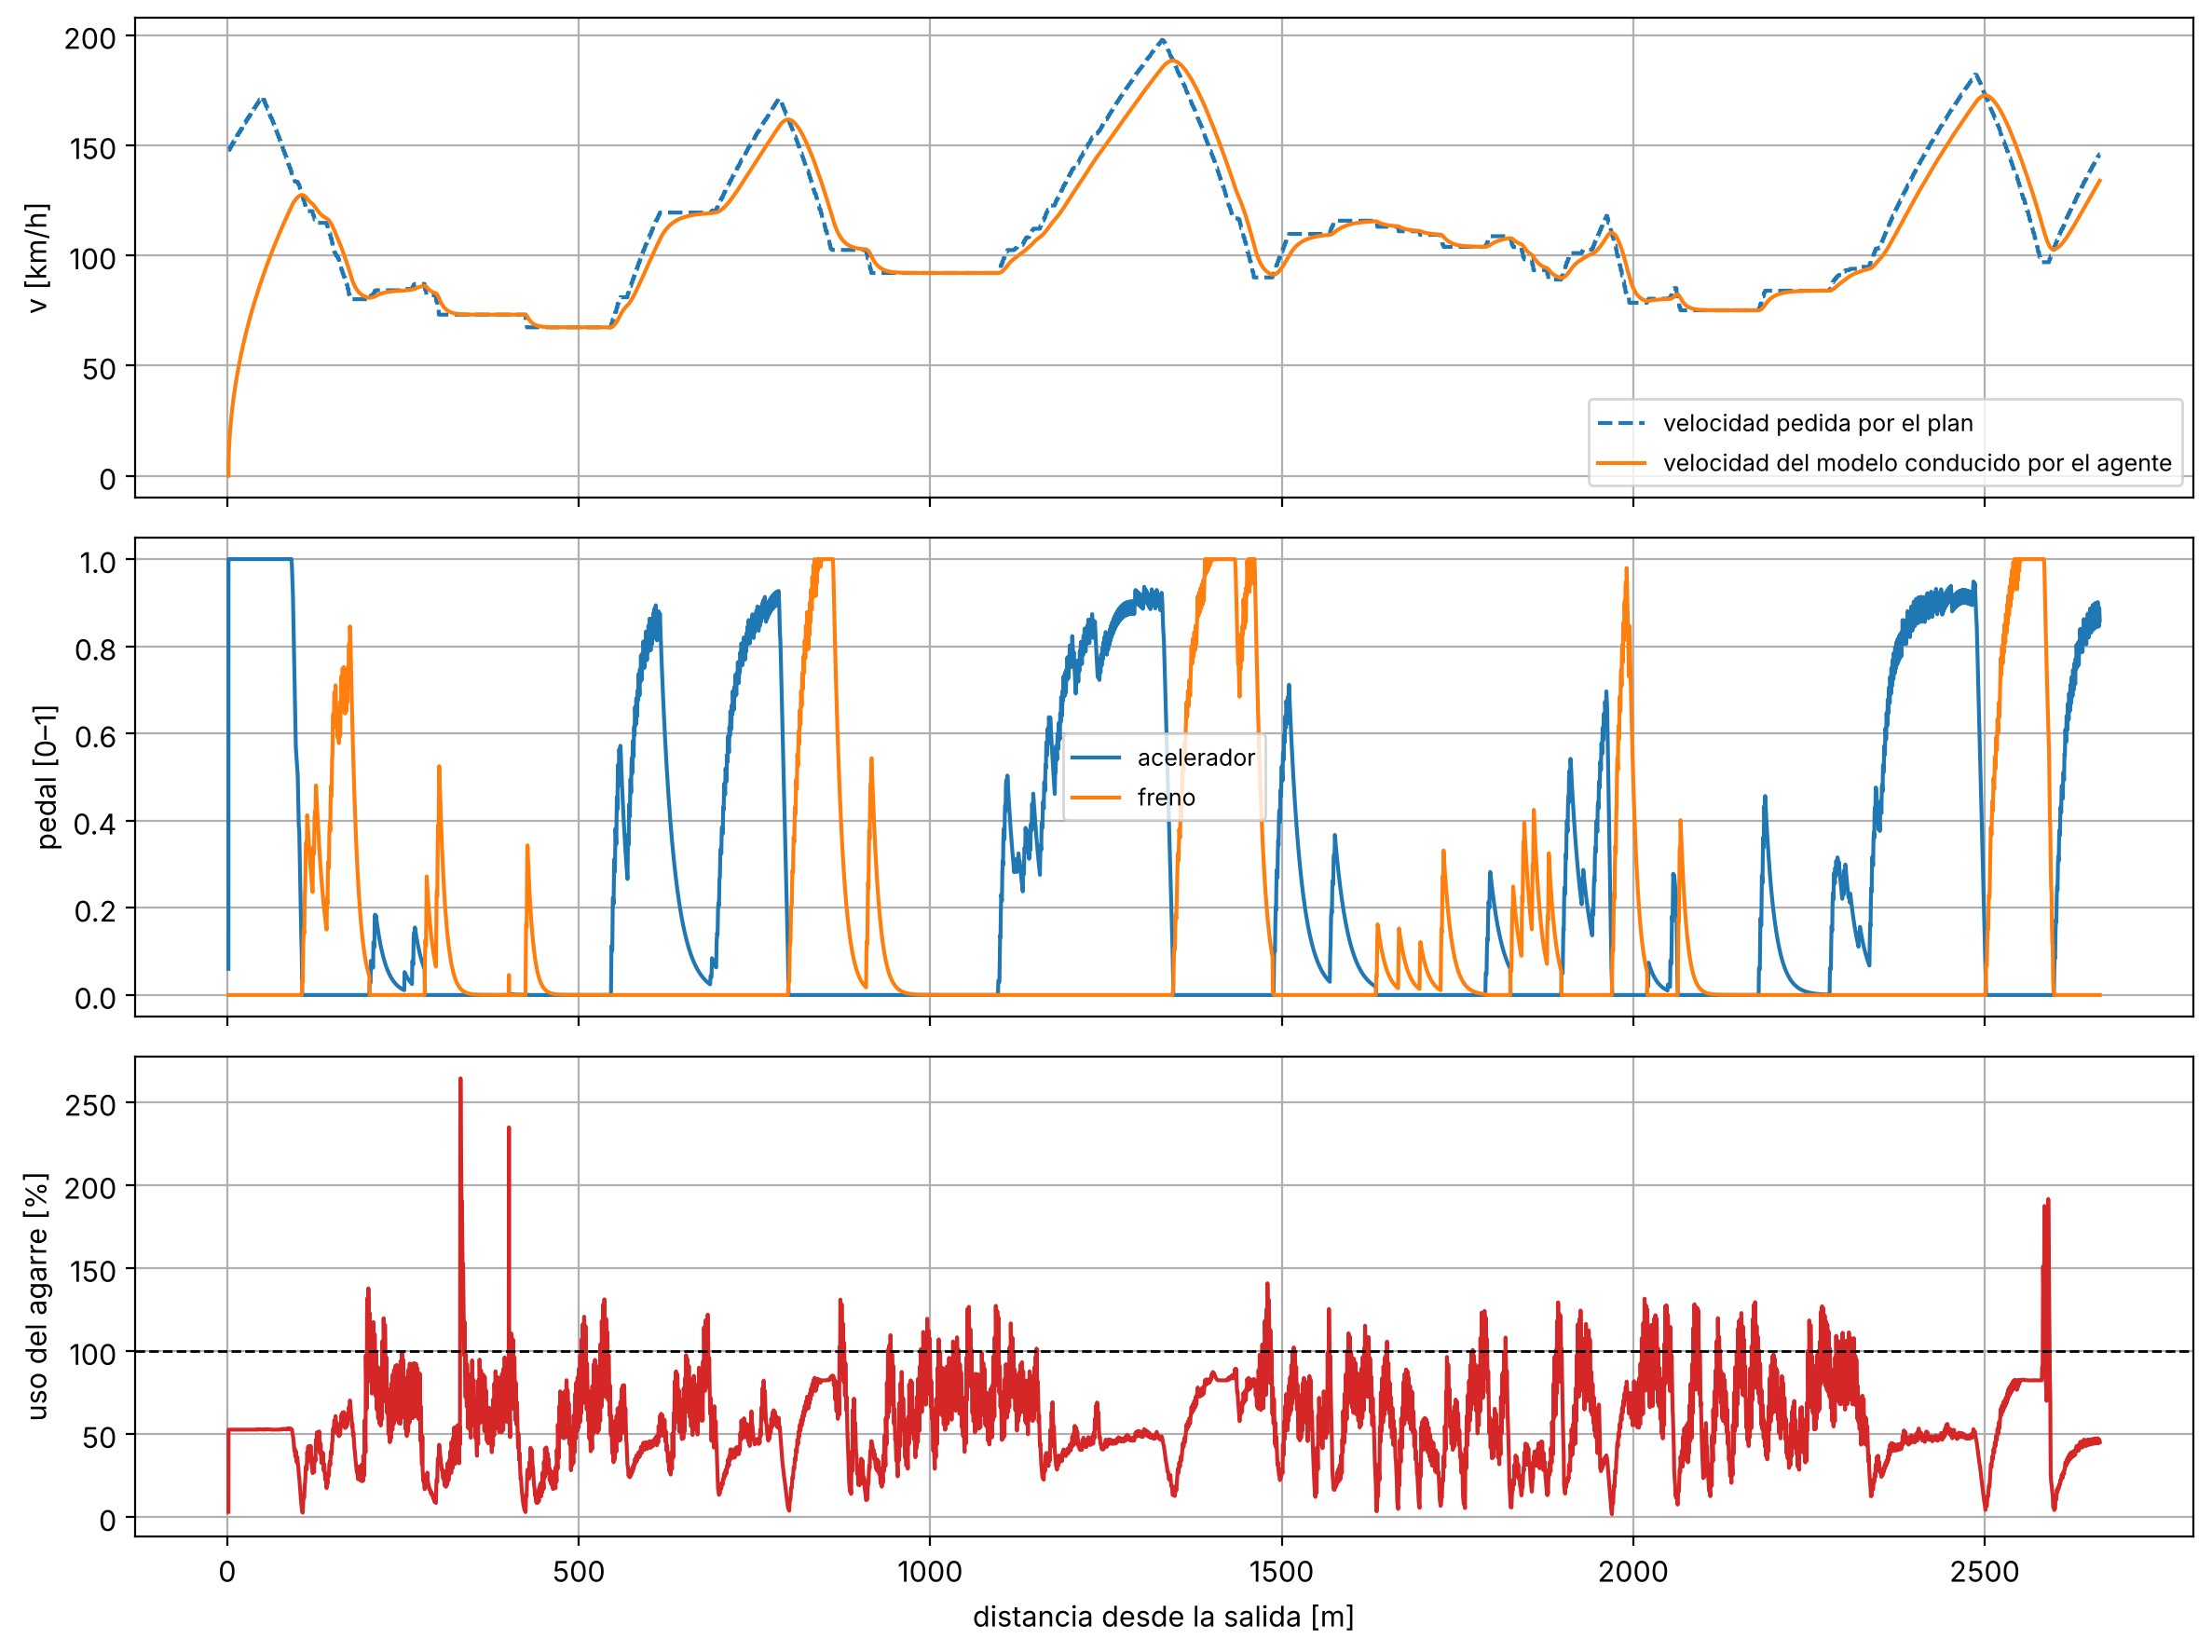

In [12]:
def vuelta_con_agente(ruta, plan, veh, dt=0.02, t_max=600.0):
    s_ruta = cfo.estaciones(ruta)
    i = int(np.searchsorted(s_ruta, S_INICIO_R))
    t0 = ruta[i + 1] - ruta[i]
    estado = mf.Estado(ruta[i, 0], ruta[i, 1], float(np.arctan2(t0[1], t0[0])), 0.0, 0.0)
    agente = AgenteConductor(veh, periodo_control_s=dt)
    agente.establecer_trayectoria(ruta)
    s_prev, t, h = S_INICIO_R, 0.0, []
    while t < t_max:
        t += dt
        s_act, error = cfo.progreso([estado.x, estado.y], ruta, s_ruta, s_prev)   # 1. avance sobre la ruta
        s_prev = max(s_prev, s_act)
        if s_prev >= S_META_R:
            break
        v_obj = cfo.controlar(agente, plan, s_ruta, s_prev, t)                    # 2. referencia del plan
        u = agente.actualizar(t, estado).controles                                # 3. mandos del agente
        a = u.acelerador * mf.aceleracion_motor(estado.velocidad_m_s, veh) - u.freno * veh.frenado_max_m_s2  # 4.
        estado = mf.paso_bicicleta(estado, a, u.direccion_rad, dt, veh)          # 5. Euler
        a_lat = estado.velocidad_m_s**2 * np.tan(estado.delta_rad) / veh.distancia_ejes_m
        h.append((t, s_prev - S_INICIO_R, estado.x, estado.y, estado.psi_rad, estado.velocidad_m_s,
                  v_obj, a, a_lat, error, u.acelerador, u.freno))
    claves = ["t", "s", "x", "y", "psi", "v", "v_obj", "a", "a_lat", "error", "acel", "freno"]
    h = dict(zip(claves, np.array(h).T))
    h["completa"] = s_prev >= S_META_R
    return h

sim = vuelta_con_agente(ruta, evaluacion, veh)
uso = np.hypot(sim["a"], sim["a_lat"]) / (veh.coef_friccion * G)
print(f"¿Completó la vuelta? {sim['completa']} | tiempo simulado: {sim['t'][-1]:.2f} s (plan: {T_plan:.2f} s, que asume salida lanzada)")
print(f"Error lateral: máximo {sim['error'].max():.2f} m, medio {sim['error'].mean():.2f} m")
print(f"Pasos que superan el círculo de fricción: {100*np.mean(uso > 1):.1f} %  (uso máximo: {100*uso.max():.0f} %)")

# Huella rectangular: ¿alguna esquina sale de la pista? (cada 10 pasos)
# Huella rectangular contra los bordes LOCALES de la pista (el ancho cambia entre ~9 y ~14 m)
normales_c = mf.normales_izquierdas(c)
borde_izq = np.sum((iz - c) * normales_c, axis=1)      # distancia del centro al borde izquierdo
borde_der = -np.sum((de - c) * normales_c, axis=1)     # distancia del centro al borde derecho
fuera = []
for j in range(0, len(sim["t"]), 10):
    esquinas = est.esquinas_rectangulo(mf.Estado(sim["x"][j], sim["y"][j], sim["psi"][j], 0.0), veh)
    i_c = np.argmin(np.linalg.norm(c - [sim["x"][j], sim["y"][j]], axis=1))
    lateral = (esquinas - c[i_c]) @ normales_c[i_c]     # desplazamiento lateral de cada esquina
    fuera.append(bool(np.any(lateral > borde_izq[i_c]) or np.any(-lateral > borde_der[i_c])))
print(f"Instantes revisados con alguna esquina fuera de los bordes locales: {sum(fuera)} de {len(fuera)}")

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(sim["s"], sim["v_obj"] * 3.6, "--", label="velocidad pedida por el plan")
ax[0].plot(sim["s"], sim["v"] * 3.6, label="velocidad del modelo conducido por el agente")
ax[0].set(ylabel="v [km/h]"); ax[0].legend(fontsize=9)
ax[1].plot(sim["s"], sim["acel"], label="acelerador"); ax[1].plot(sim["s"], sim["freno"], label="freno")
ax[1].set(ylabel="pedal [0–1]"); ax[1].legend(fontsize=9)
ax[2].plot(sim["s"], 100 * uso, c="C3"); ax[2].axhline(100, c="k", ls="--", lw=1)
ax[2].set(xlabel="distancia desde la salida [m]", ylabel="uso del agarre [%]")
plt.tight_layout(); plt.show()

**Interpretación.** 
- El agente sigue el plan con un error lateral medio de unos centímetros. El error máximo, de algunos metros, aparece en la curva más exigente, donde el agente reacciona tarde. Aun así completa la vuelta con la huella dentro de los bordes: la referencia **es físicamente seguible** por un vehículo con la cinemática de bicicleta.
- La velocidad real va un poco detrás de la pedida en cada cambio: el control proporcional necesita un error para reaccionar y los pedales tienen un límite de cambio por segundo. Por eso aparece un retraso en las frenadas y en las salidas de curva.
- La vuelta simulada sale desde cero, mientras que el plan asume que el auto ya viene lanzado desde los 200 m de margen; esa diferencia explica buena parte del tiempo extra de la simulación.
- El uso del agarre supera el 100 % en algunos instantes: el agente frena o gira un poco tarde y pide más de lo que el círculo de fricción permite. En Assetto Corsa, en esos instantes el auto deslizaría; nuestro modelo cinemático no puede deslizar, solo lo **detecta**. Esto indica dónde el plan queda al límite.

## 8. Validación del método numérico

Probamos las funciones del proyecto en casos con solución exacta. Si las reproducen, confiamos más en ellas cuando no hay solución exacta (la vuelta completa).

### 8.1 Curvatura de un círculo

Para puntos sobre un círculo de radio $R$, la fórmula de tres puntos debe dar exactamente $\kappa = 1/R$, con cualquier separación entre puntos.

In [13]:
for R in [20, 50, 150]:
    for ds in [0.5, 2.0, 5.0]:
        theta = np.arange(0, 2 * np.pi, ds / R)
        circulo = np.column_stack([R * np.cos(theta), R * np.sin(theta)])
        k = mf.curvaturas_de_puntos(circulo)
        print(f"R = {R:4d} m, Δs = {ds:3.1f} m → κ calculada = {k.mean():.6f} 1/m, exacta 1/R = {1/R:.6f} 1/m, "
              f"error relativo = {abs(k.mean()*R - 1):.1e}")

R =   20 m, Δs = 0.5 m → κ calculada = 0.050000 1/m, exacta 1/R = 0.050000 1/m, error relativo = 1.1e-15
R =   20 m, Δs = 2.0 m → κ calculada = 0.050000 1/m, exacta 1/R = 0.050000 1/m, error relativo = 1.1e-16
R =   20 m, Δs = 5.0 m → κ calculada = 0.050000 1/m, exacta 1/R = 0.050000 1/m, error relativo = 1.1e-16
R =   50 m, Δs = 0.5 m → κ calculada = 0.020000 1/m, exacta 1/R = 0.020000 1/m, error relativo = 1.1e-16
R =   50 m, Δs = 2.0 m → κ calculada = 0.020000 1/m, exacta 1/R = 0.020000 1/m, error relativo = 8.9e-16
R =   50 m, Δs = 5.0 m → κ calculada = 0.020000 1/m, exacta 1/R = 0.020000 1/m, error relativo = 8.9e-16
R =  150 m, Δs = 0.5 m → κ calculada = 0.006667 1/m, exacta 1/R = 0.006667 1/m, error relativo = 3.8e-14
R =  150 m, Δs = 2.0 m → κ calculada = 0.006667 1/m, exacta 1/R = 0.006667 1/m, error relativo = 2.9e-15
R =  150 m, Δs = 5.0 m → κ calculada = 0.006667 1/m, exacta 1/R = 0.006667 1/m, error relativo = 0.0e+00


**Interpretación.** El error es del orden del redondeo de la computadora: la curvatura de tres puntos es exacta para un círculo, porque los tres puntos determinan justamente el círculo que pasa por ellos. En una pista real, el error de la curvatura viene del ruido de los datos, no de la fórmula.

### 8.2 Frenado en recta y efecto de $\Delta t$

Frenamos desde $v_0 = 100$ km/h con desaceleración constante $b$ usando `paso_bicicleta` y medimos la distancia hasta detenerse. La solución exacta es $d = v_0^2/2b$.

**Predicción antes de ejecutar.** Euler explícito usa la velocidad del **inicio** de cada paso para avanzar la posición. Al frenar, esa velocidad es mayor que la media del paso, así que el método **sobreestima** la distancia. El exceso en cada paso es $\tfrac{1}{2}b\Delta t^2$, y hay $v_0/(b\Delta t)$ pasos, así que el error total es $\approx \tfrac{1}{2}v_0\Delta t$: **proporcional a $\Delta t$** (método de primer orden). Si duplicamos $\Delta t$, el error se duplica.

Δt = 0.200 s → error =  +2.7814 m  (predicción ½ v₀ Δt =  2.7778 m)
Δt = 0.100 s → error =  +1.3906 m  (predicción ½ v₀ Δt =  1.3889 m)
Δt = 0.050 s → error =  +0.6953 m  (predicción ½ v₀ Δt =  0.6944 m)
Δt = 0.020 s → error =  +0.2781 m  (predicción ½ v₀ Δt =  0.2778 m)
Δt = 0.010 s → error =  +0.1390 m  (predicción ½ v₀ Δt =  0.1389 m)
Δt = 0.005 s → error =  +0.0695 m  (predicción ½ v₀ Δt =  0.0694 m)
Δt = 0.001 s → error =  +0.0139 m  (predicción ½ v₀ Δt =  0.0139 m)


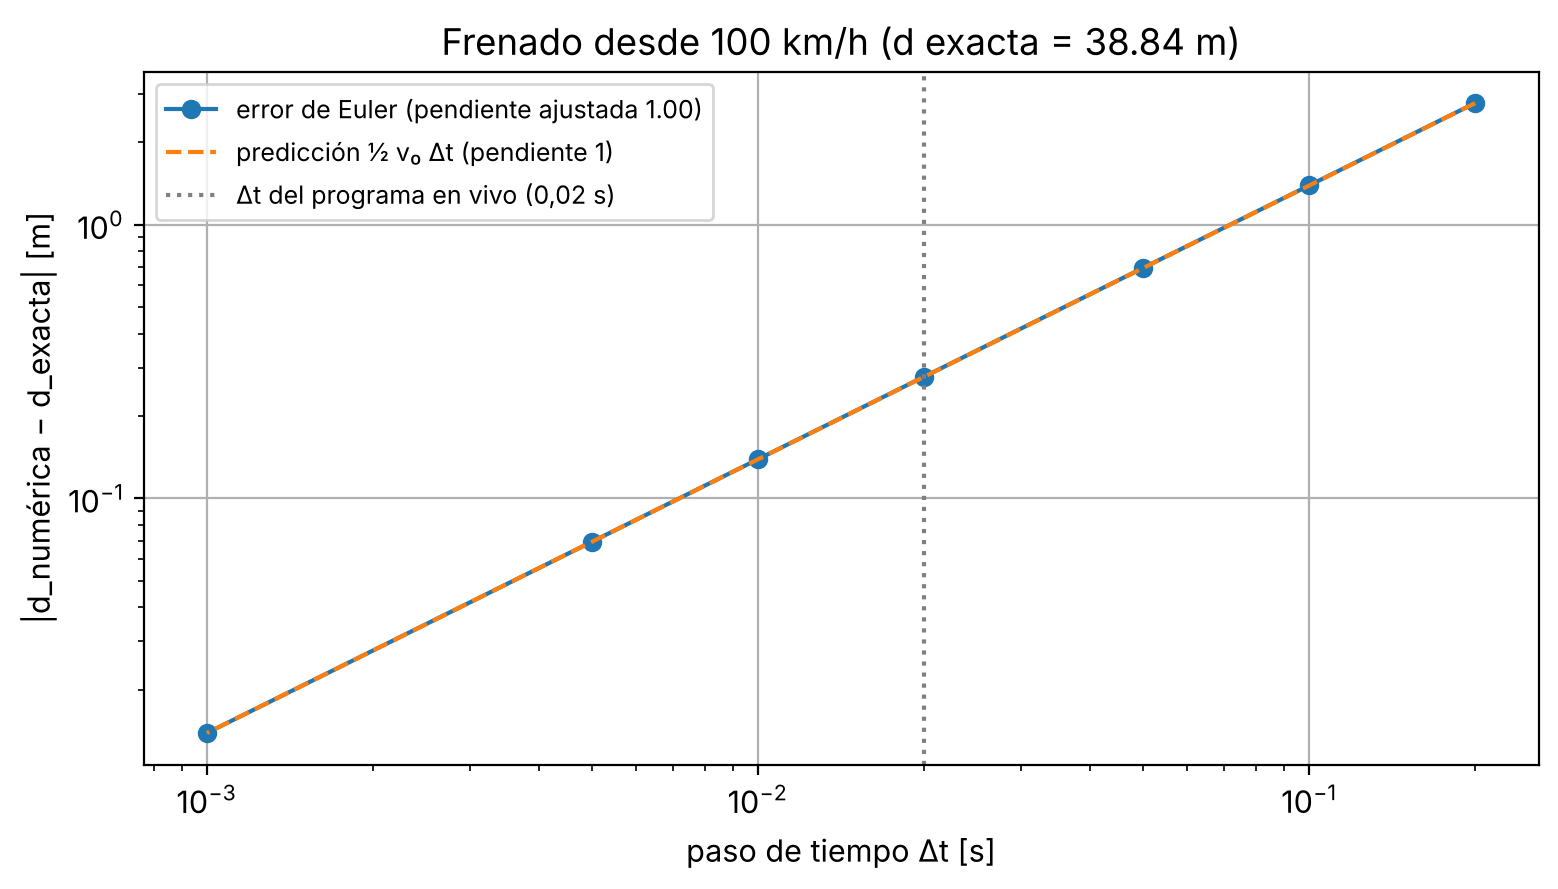

In [14]:
def frenar_en_recta(v0, dt):
    e = mf.Estado(0.0, 0.0, 0.0, v0, 0.0)
    while e.velocidad_m_s > 0:
        e = mf.paso_bicicleta(e, -veh.frenado_max_m_s2, 0.0, dt, veh)
    return e.x

v0 = 100 / 3.6
d_exacta = mf.distancia_frenado(v0, 0.0, veh.frenado_max_m_s2)
dts = np.array([0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.001])
errores = np.array([frenar_en_recta(v0, dt) - d_exacta for dt in dts])
for dt, e in zip(dts, errores):
    print(f"Δt = {dt:5.3f} s → error = {e:+8.4f} m  (predicción ½ v₀ Δt = {0.5*v0*dt:7.4f} m)")
pendiente = np.polyfit(np.log(dts), np.log(np.abs(errores)), 1)[0]

plt.loglog(dts, np.abs(errores), "o-", label=f"error de Euler (pendiente ajustada {pendiente:.2f})")
plt.loglog(dts, 0.5 * v0 * dts, "--", label="predicción ½ v₀ Δt (pendiente 1)")
plt.axvline(cfo.INTERVALO_CONTROL_S, c="gray", ls=":", label="Δt del programa en vivo (0,02 s)")
plt.xlabel("paso de tiempo Δt [s]"); plt.ylabel("|d_numérica − d_exacta| [m]")
plt.title(f"Frenado desde 100 km/h (d exacta = {d_exacta:.2f} m)"); plt.legend(fontsize=9); plt.show()

**Interpretación.** Los errores coinciden con la predicción $\tfrac{1}{2}v_0\Delta t$ y la pendiente en escala log-log es 1: el método es de primer orden. Con $\Delta t = 0{,}02$ s el error es de unos 0,3 m sobre unos 39 m de frenado, menos del 1 %; frente a otras incertidumbres del modelo (el $b$ real cambia con la velocidad, sección 4) es despreciable.

### 8.3 Giro con ángulo constante

Con $\delta$ fijo, la bicicleta debe recorrer un círculo de radio $R = L/\tan\delta$. Simulamos 3 vueltas a un círculo de 50 m a 20 m/s.

**Predicción antes de ejecutar.** En cada paso de Euler, la orientación aumenta exactamente $\omega\Delta t$ (con $\omega = v/R$) y el auto avanza un segmento recto de longitud $v\Delta t$ en la dirección que tenía al inicio del paso. Entonces la trayectoria numérica es un **polígono regular** de lado $v\Delta t$: se cierra sobre sí mismo y no se aleja vuelta tras vuelta. Ese polígono está inscrito en un círculo de radio

$$R_{num} = \frac{v\Delta t}{2\sin(\omega\Delta t/2)} \approx R\left(1 + \frac{(\omega\Delta t)^2}{24}\right)$$

así que el error del radio debería ser muy pequeño y proporcional a $\Delta t^2$. Medimos el radio ajustando un círculo por mínimos cuadrados a todos los puntos simulados.

In [15]:
R_obj, v_giro = 50.0, 20.0
delta = float(mf.curvatura_a_direccion(1 / R_obj, veh))
print(f"Ángulo de ruedas δ = {np.degrees(delta):.2f}° → volante ≈ {np.degrees(mf.giro_ruedas_a_volante(delta, veh)):.0f}° "
      f"| R = L/tan δ = {mf.direccion_a_radio(delta, veh):.2f} m")
print(f"a_lat = v²/R = {v_giro**2/R_obj:.2f} m/s² ≤ μg = {veh.coef_friccion*G:.2f} m/s² → maniobra viable: "
      f"{bool(mf.aceleracion_total_admisible(v_giro**2/R_obj, 0.0, veh))}")

for dt in [0.2, 0.1, 0.05, 0.02, 0.01]:
    e = mf.Estado(0.0, 0.0, 0.0, v_giro, delta)
    xs, ys = [], []
    for _ in range(int(3 * 2 * np.pi * R_obj / v_giro / dt)):
        e = mf.paso_bicicleta(e, 0.0, delta, dt, veh)
        xs.append(e.x); ys.append(e.y)
    xs, ys = np.array(xs), np.array(ys)
    # círculo x² + y² + Dx + Ey + F = 0 ajustado por mínimos cuadrados
    D, E, F = np.linalg.lstsq(np.c_[xs, ys, np.ones_like(xs)], -(xs**2 + ys**2), rcond=None)[0]
    R_num = np.sqrt(D**2 / 4 + E**2 / 4 - F)
    R_pred = v_giro * dt / (2 * np.sin(v_giro / R_obj * dt / 2))
    print(f"Δt = {dt:4.2f} s → radio medido = {R_num:8.4f} m | predicción vΔt/(2 sin(ωΔt/2)) = {R_pred:8.4f} m | error = {R_num - R_obj:+.4f} m")

Ángulo de ruedas δ = 2.81° → volante ≈ 29° | R = L/tan δ = 50.00 m
a_lat = v²/R = 8.00 m/s² ≤ μg = 12.07 m/s² → maniobra viable: True
Δt = 0.20 s → radio medido =  50.0133 m | predicción vΔt/(2 sin(ωΔt/2)) =  50.0133 m | error = +0.0133 m
Δt = 0.10 s → radio medido =  50.0033 m | predicción vΔt/(2 sin(ωΔt/2)) =  50.0033 m | error = +0.0033 m
Δt = 0.05 s → radio medido =  50.0008 m | predicción vΔt/(2 sin(ωΔt/2)) =  50.0008 m | error = +0.0008 m
Δt = 0.02 s → radio medido =  50.0001 m | predicción vΔt/(2 sin(ωΔt/2)) =  50.0001 m | error = +0.0001 m
Δt = 0.01 s → radio medido =  50.0000 m | predicción vΔt/(2 sin(ωΔt/2)) =  50.0000 m | error = +0.0000 m


**Interpretación.** El radio medido coincide con la predicción del polígono y su error baja como $\Delta t^2$ (al dividir el paso entre 2, el error se divide entre 4): en el giro, Euler es mucho más preciso que en el frenado, porque la orientación avanza exactamente lo mismo en cada paso. Lo que se corre con $\Delta t$ es el centro del círculo, medio paso; en la conducción eso lo corrige el agente en cada ciclo. También aparece un límite del modelo cinemático: el radio **no depende de la velocidad**, así que el modelo describiría el mismo círculo a cualquier $v$. Por eso necesitamos aparte el círculo de fricción para saber si la maniobra es posible.

### 8.4 Efecto de $\Delta t$ en la vuelta completa

**Pregunta típica de la sustentación: "Predigan qué pasa si duplicamos el paso de tiempo".** El agente actúa una vez por paso, así que con $\Delta t$ mayor reacciona más tarde y Euler acumula más error por paso; esperamos que el tiempo de vuelta y el error lateral cambien poco entre 0,01 y 0,02 s y más con pasos grandes. Lo ejecutamos:

In [16]:
resultados_dt = []
for dt in [0.08, 0.04, 0.02, 0.01]:
    h = vuelta_con_agente(ruta, evaluacion, veh, dt=dt)
    resultados_dt.append((dt, h["completa"], h["t"][-1], h["error"].max()))
    print(f"Δt = {dt:4.2f} s → completa: {h['completa']} | tiempo de vuelta = {h['t'][-1]:7.2f} s | error lateral máx = {h['error'].max():.2f} m")

Δt = 0.08 s → completa: True | tiempo de vuelta =   97.44 s | error lateral máx = 5.16 m


Δt = 0.04 s → completa: True | tiempo de vuelta =   97.32 s | error lateral máx = 5.06 m


Δt = 0.02 s → completa: True | tiempo de vuelta =   97.04 s | error lateral máx = 3.62 m


Δt = 0.01 s → completa: True | tiempo de vuelta =   97.02 s | error lateral máx = 3.62 m


**Interpretación.** El tiempo de vuelta converge al reducir $\Delta t$: la diferencia entre 0,02 s y 0,01 s es mucho menor que entre pasos grandes. Esto justifica usar $\Delta t = 0{,}02$ s en vivo: es el mayor paso que deja el resultado prácticamente igual al de un paso más fino, y deja 20 ms por ciclo para leer la telemetría y enviar los mandos.

## 9. Análisis complementario: visibilidad necesaria para frenar

### 9.1 Distancia mínima que hay que ver antes de una curva

Si el auto llega a $v_0$ y la curva permite $v_c = \sqrt{\mu g R}$, debe empezar a frenar a una distancia $d = (v_0^2 - v_c^2)/2b$ antes de la curva. Esa es la distancia de pista que necesita conocer: la **visibilidad mínima**. Cuando el frenado está limitado por el agarre ($b = \mu g$):

$$D_{min} = \frac{v_0^2 - \mu g R}{2\mu g} = \frac{v_0^2}{2\mu g} - \frac{R}{2}\qquad (v_0 > \sqrt{\mu g R})$$

Usamos las funciones del proyecto `velocidad_maxima_curva` y `distancia_frenado`.

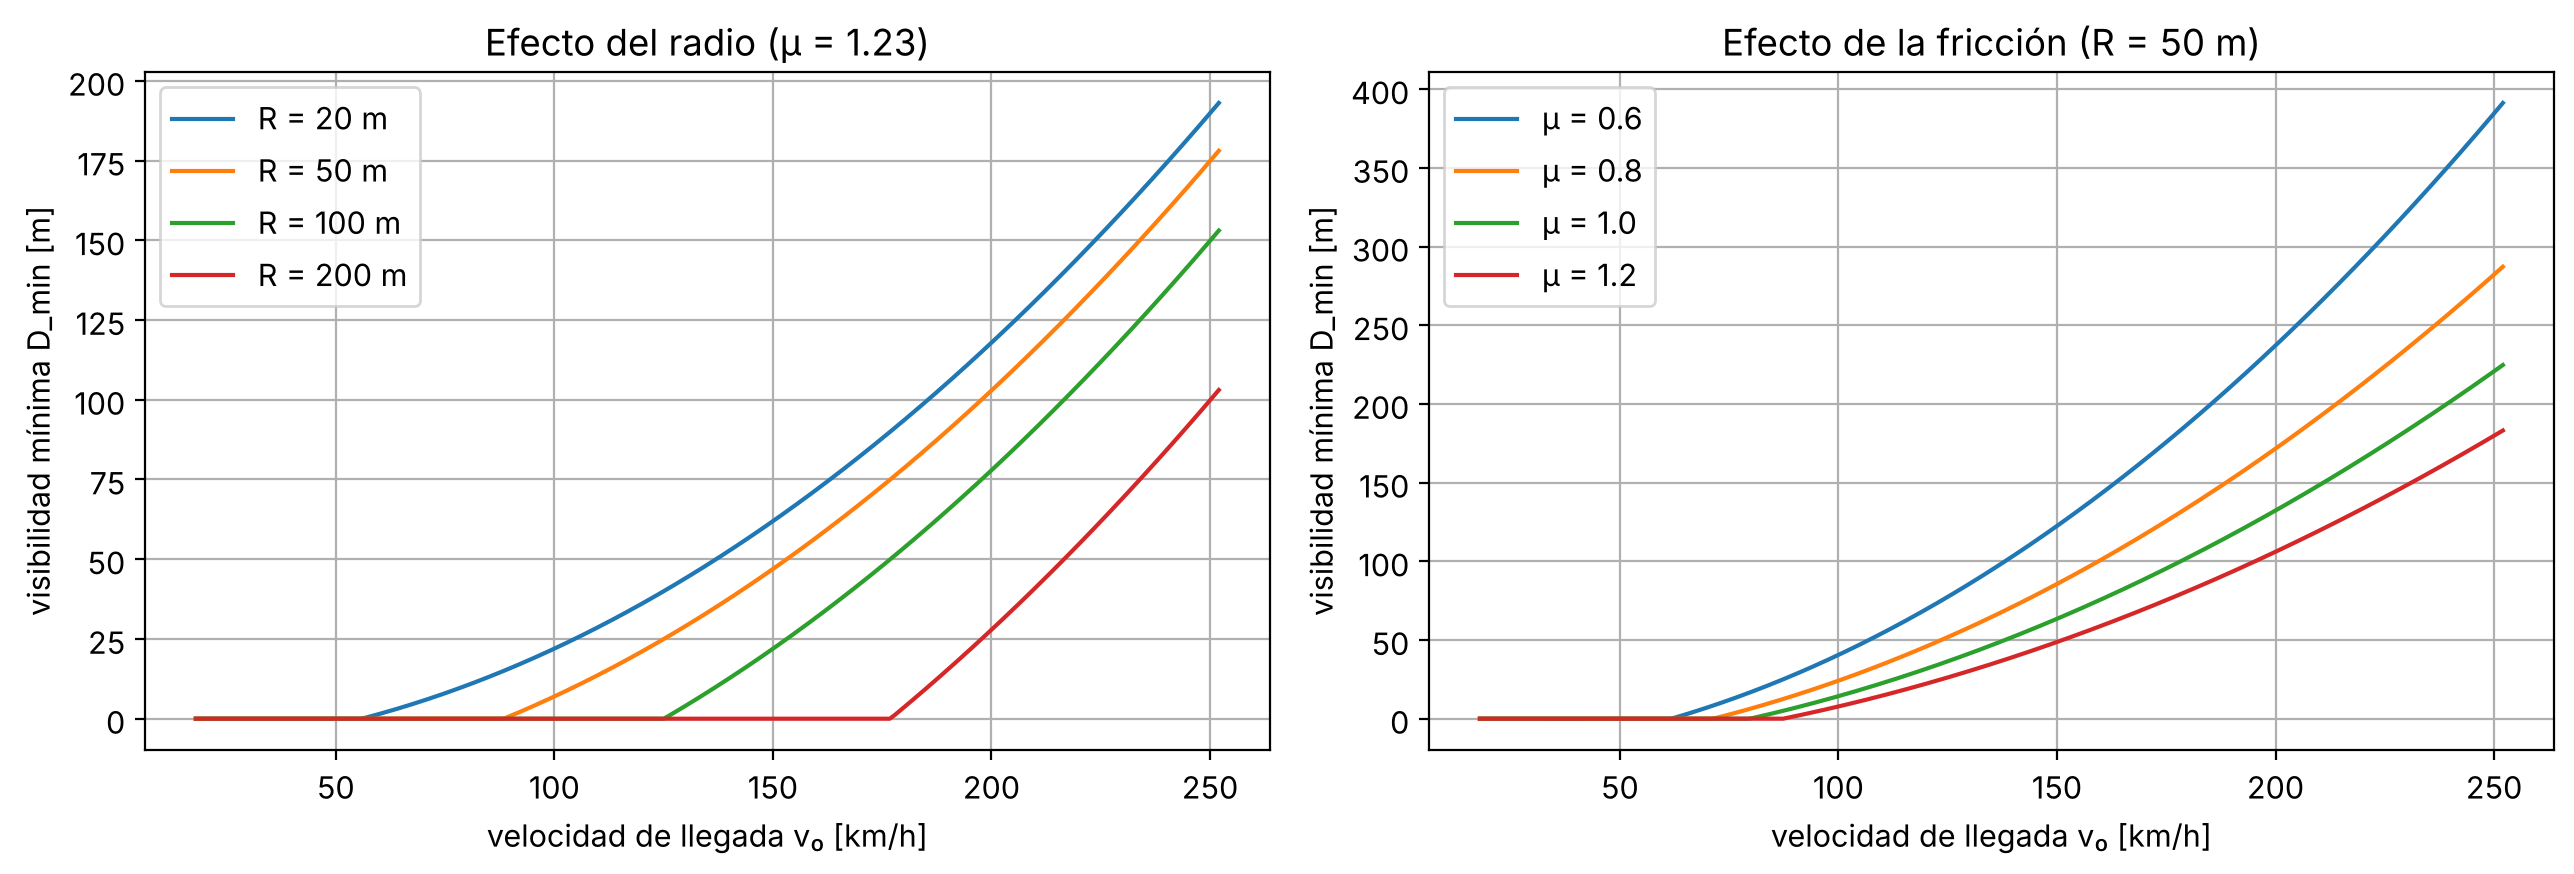

Ejemplo: llegar a 180 km/h a una curva de 50 m
  μ = 0.8: D_min =  134.3 m
  μ = 1.0: D_min =  102.4 m
  μ = 1.2: D_min =   81.2 m


In [17]:
def visibilidad_minima(v0, R, mu, b=None):
    vehiculo = mf.Vehiculo(coef_friccion=mu)
    b = mu * G if b is None else b
    v_c = mf.velocidad_maxima_curva(1 / R, vehiculo)
    return mf.distancia_frenado(v0, v_c, b) if v0 > v_c else 0.0

v0s = np.linspace(5, 70, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for R in [20, 50, 100, 200]:
    a1.plot(v0s * 3.6, [visibilidad_minima(v, R, veh.coef_friccion) for v in v0s], label=f"R = {R} m")
a1.set(xlabel="velocidad de llegada v₀ [km/h]", ylabel="visibilidad mínima D_min [m]",
       title=f"Efecto del radio (μ = {veh.coef_friccion})"); a1.legend()
for mu in [0.6, 0.8, 1.0, 1.2]:
    a2.plot(v0s * 3.6, [visibilidad_minima(v, 50, mu) for v in v0s], label=f"μ = {mu}")
a2.set(xlabel="velocidad de llegada v₀ [km/h]", ylabel="visibilidad mínima D_min [m]",
       title="Efecto de la fricción (R = 50 m)"); a2.legend()
plt.tight_layout(); plt.show()

print("Ejemplo: llegar a 180 km/h a una curva de 50 m")
for mu in [0.8, 1.0, 1.2]:
    print(f"  μ = {mu}: D_min = {visibilidad_minima(50.0, 50, mu):6.1f} m")

**Interpretación.** 
- **Con $v_0$:** $D_{min}$ crece con $v_0^2$. Duplicar la velocidad de llegada casi cuadruplica la distancia que hay que ver.
- **Con $R$:** cada curva tiene un umbral $v_0 = \sqrt{\mu g R}$ por debajo del cual no hace falta frenar ($D_{min} = 0$). Por encima, una curva más abierta resta $R/2$: las curvas de radio grande necesitan menos visibilidad.
- **Con $\mu$:** $D_{min}$ va como $1/\mu$ (para $v_0$ grande). Con menos agarre (pista mojada, neumáticos fríos) hay que ver mucho más lejos.

### 9.2 Cuánto tiempo cuesta ver solo $D_v$ metros

El planificador del proyecto conoce la vuelta entera. Si el auto solo conociera los siguientes $D_v$ metros, en cada punto tendría que suponer que justo después de lo visible puede aparecer la curva más lenta del circuito ($v_c$ = velocidad mínima del plan) y respetar $v \le \sqrt{v_c^2 + 2bD_v}$ (`mf.velocidad_segura_visibilidad`). Después, una pasada hacia adelante recalcula cuánto puede acelerar el auto con ese nuevo tope.

D_v =   25 m → tiempo de vuelta  102.46 s (+ 9.33 s frente a conocer toda la vuelta)
D_v =   50 m → tiempo de vuelta   95.91 s (+ 2.78 s frente a conocer toda la vuelta)
D_v =   75 m → tiempo de vuelta   93.90 s (+ 0.77 s frente a conocer toda la vuelta)
D_v =  100 m → tiempo de vuelta   93.27 s (+ 0.14 s frente a conocer toda la vuelta)
D_v =  150 m → tiempo de vuelta   93.13 s (+ 0.00 s frente a conocer toda la vuelta)
D_v =  200 m → tiempo de vuelta   93.13 s (+ 0.00 s frente a conocer toda la vuelta)
D_v =  300 m → tiempo de vuelta   93.13 s (+ 0.00 s frente a conocer toda la vuelta)


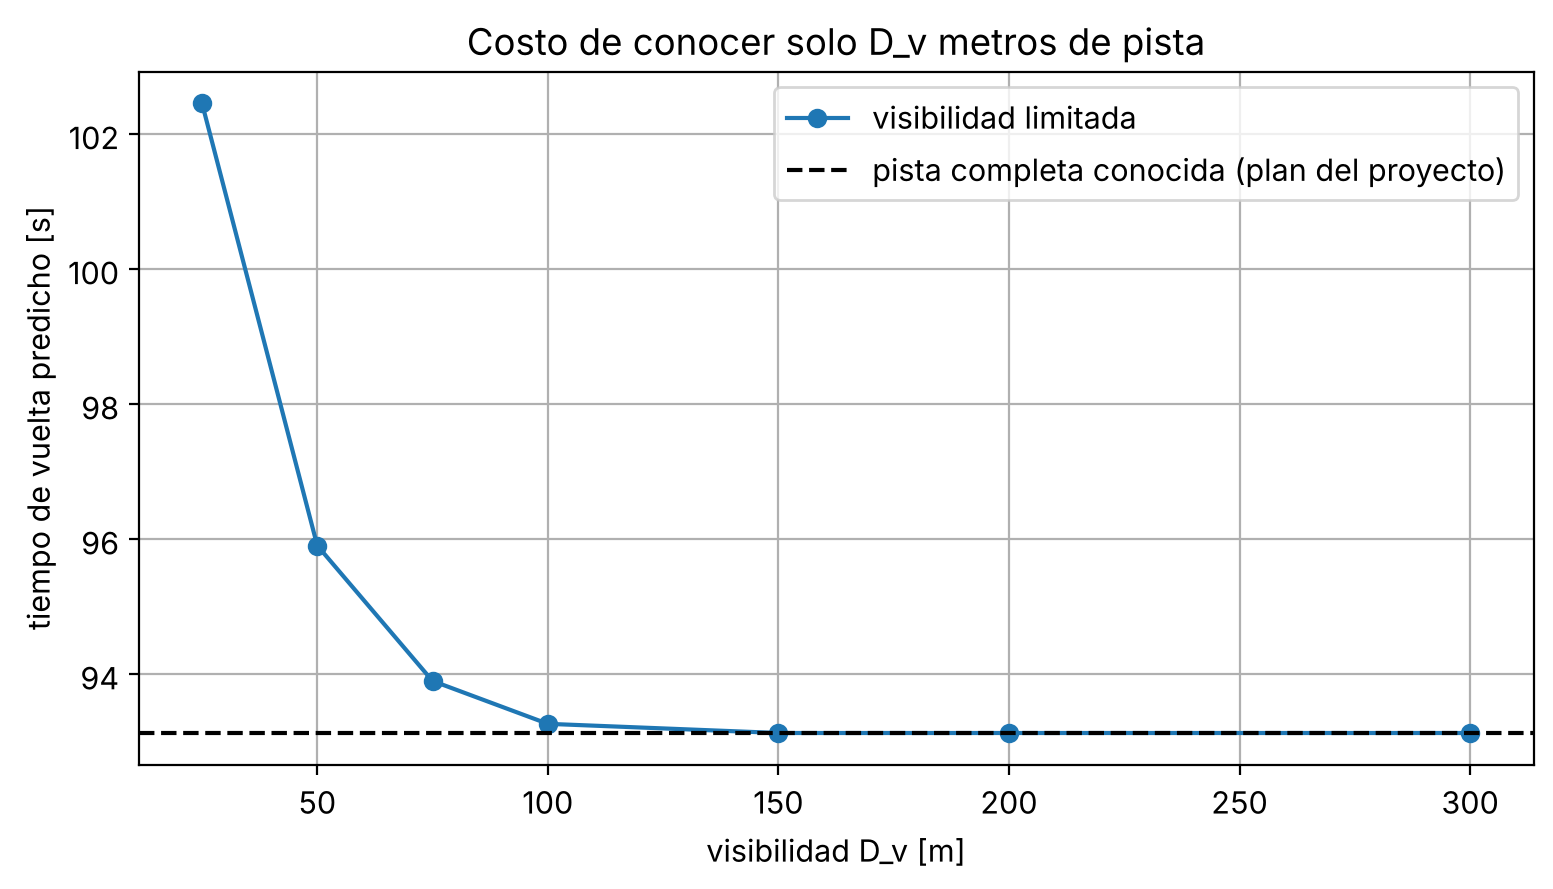

In [18]:
def perfil_con_visibilidad(ruta, plan, veh, D_v):
    s = cfo.estaciones(ruta)
    k = plan.curvaturas_menos1
    v_c = float(plan.velocidades_m_s[(s > S_INICIO_R) & (s < S_META_R)].min())   # curva más lenta conocida
    tope = np.minimum(plan.velocidades_m_s, mf.velocidad_segura_visibilidad(v_c, D_v, veh.frenado_max_m_s2))
    v = tope.copy()
    for i in range(len(s) - 1):   # pasada hacia adelante: motor y agarre restante
        a = min(mf.aceleracion_motor(v[i], veh), float(mf.aceleracion_longitudinal_por_agarre(v[i], k[i], veh)))
        v[i + 1] = min(v[i + 1], mf.acelerar_en_distancia(v[i], a, s[i + 1] - s[i]))
    return v

Dvs = [25, 50, 75, 100, 150, 200, 300]
tiempos_vis = [tiempo_vuelta(ruta, perfil_con_visibilidad(ruta, evaluacion, veh, D)) for D in Dvs]
for D, T in zip(Dvs, tiempos_vis):
    print(f"D_v = {D:4d} m → tiempo de vuelta {T:7.2f} s (+{T - T_plan:5.2f} s frente a conocer toda la vuelta)")
plt.plot(Dvs, tiempos_vis, "o-", label="visibilidad limitada")
plt.axhline(T_plan, c="k", ls="--", label="pista completa conocida (plan del proyecto)")
plt.xlabel("visibilidad D_v [m]"); plt.ylabel("tiempo de vuelta predicho [s]")
plt.title("Costo de conocer solo D_v metros de pista"); plt.legend(); plt.show()

**Interpretación.** Con poca visibilidad el auto debe ir lento incluso en recta, porque no sabe qué viene. A medida que $D_v$ crece, el tiempo baja hasta igualar al plan con pista completa: a partir de ese punto, ver más lejos ya no aporta nada, porque la visibilidad supera la distancia de frenado más larga de la vuelta. Ese valor de $D_v$ es la distancia de pista que el planificador necesita conocer para no perder rendimiento con este auto en esta pista.

## 10. Sensibilidad a los parámetros

Variamos $\pm 20\,\%$ el coeficiente de fricción $\mu$, el frenado $b$ y la potencia $P$, y reevaluamos el tiempo predicho **sobre la misma ruta optimizada** (sin volver a optimizar). Así vemos qué parámetro pesa más en el tiempo de vuelta y, por tanto, cuál vale más la pena medir bien.

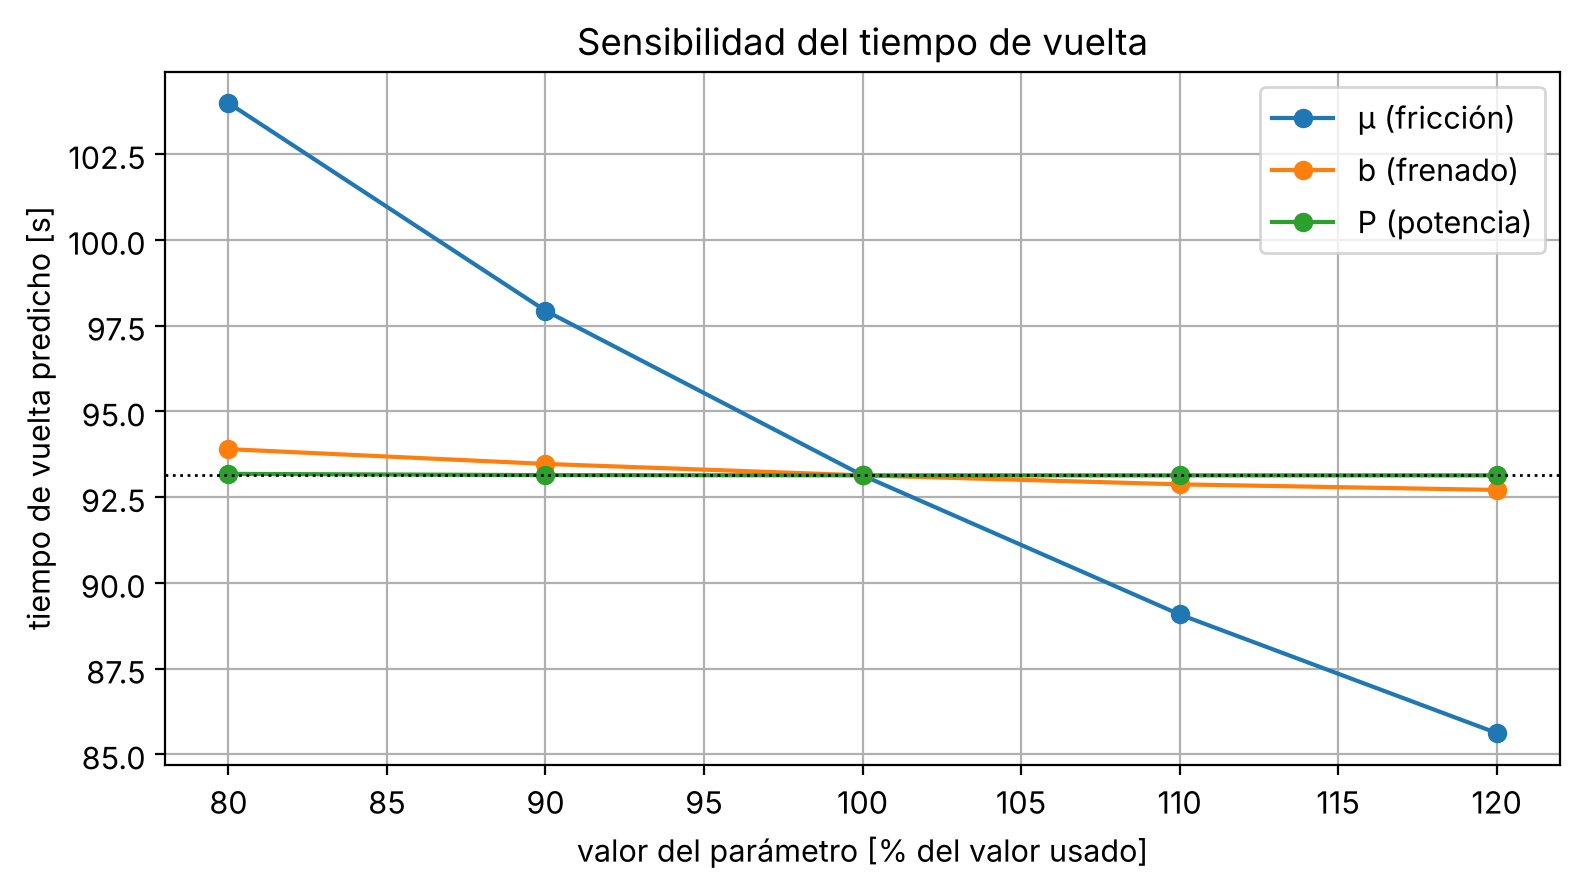

In [19]:
from dataclasses import replace
factores = [0.8, 0.9, 1.0, 1.1, 1.2]
campos = {"μ (fricción)": "coef_friccion", "b (frenado)": "frenado_max_m_s2", "P (potencia)": "potencia_util_w"}
for nombre, campo in campos.items():
    tiempos = []
    for f in factores:
        v_mod = replace(veh, **{campo: getattr(veh, campo) * f})
        e = est.evaluar_trayectoria(ruta, v_mod, velocidad_entrada_m_s=0.0, tope_velocidad_m_s=cfo.TOPE_EVALUADOR_M_S)
        tiempos.append(tiempo_vuelta(ruta, e.velocidades_m_s))
    plt.plot(np.array(factores) * 100, tiempos, "o-", label=nombre)
plt.axhline(T_plan, c="k", ls=":", lw=1)
plt.xlabel("valor del parámetro [% del valor usado]"); plt.ylabel("tiempo de vuelta predicho [s]")
plt.title("Sensibilidad del tiempo de vuelta"); plt.legend(); plt.show()

**Interpretación.** La curva más inclinada es la del parámetro que más influye en el tiempo. La fricción $\mu$ suele dominar, porque fija la velocidad en todas las curvas ($v_{max} \propto \sqrt{\mu}$); el frenado solo cambia las zonas de frenada y la potencia solo las rectas largas. Por eso $\mu$ es el parámetro que más conviene calibrar contra Assetto Corsa, por ejemplo midiendo la velocidad máxima sostenible en una curva de radio conocido.

## 11. Comparación con 3 vueltas reales en Assetto Corsa

En el computador con el juego, el agente manejó el Porsche en Tocancipá siguiendo exactamente el plan de `plan_compartido.json`, durante 3 vueltas seguidas desde el auto detenido. El programa guardó una muestra por ciclo de control (~50 por segundo) en `datos/telemetria_ac.csv`: tiempo, distancia recorrida sobre la línea central, velocidad, velocidad pedida, pedales, volante y distancia a la línea central.

Comparamos tres cosas sobre la misma pista y la misma ruta: el **plan** (lo que predice el modelo), la **simulación** de la sección 7 (el agente manejando nuestra bicicleta) y **Assetto Corsa** (lo que hizo el auto en el simulador).

In [20]:
tel = np.genfromtxt(ARCHIVO_TELEMETRIA, delimiter=",", names=True)
dist_ac, t_ac, v_ac = tel["distance_m"], tel["time_s"], tel["speed_kmh"]
print(f"Muestras: {len(t_ac)} | intervalo medio entre muestras: {1000*np.median(np.diff(t_ac)):.1f} ms | duración: {t_ac[-1]:.1f} s")

# Tiempo de cada vuelta: instante en que la distancia recorrida cruza 1, 2 y 3 vueltas (interpolado)
cruces = [float(np.interp(n * LONGITUD, dist_ac, t_ac)) for n in (1, 2, 3)]
vueltas_ac = np.diff([0.0] + cruces)
print(f"\n{'':42s} {'tiempo':>9s}")
print(f"{'Plan (modelo, salida lanzada)':42s} {T_plan:8.2f} s")
print(f"{'Simulación con el agente (detenido)':42s} {sim['t'][-1]:8.2f} s")
for n, T in enumerate(vueltas_ac, 1):
    salida = "desde detenido" if n == 1 else "lanzada"
    print(f"{f'Assetto Corsa, vuelta {n} ({salida})':42s} {T:8.2f} s")
print(f"\nVueltas lanzadas en AC frente al plan: {vueltas_ac[1:].mean() - T_plan:+.2f} s "
      f"({100*(vueltas_ac[1:].mean() / T_plan - 1):+.1f} %) | diferencia entre vuelta 2 y 3: {abs(vueltas_ac[2]-vueltas_ac[1]):.2f} s")

Muestras: 14317 | intervalo medio entre muestras: 20.3 ms | duración: 290.8 s

                                              tiempo
Plan (modelo, salida lanzada)                 93.13 s
Simulación con el agente (detenido)           97.04 s
Assetto Corsa, vuelta 1 (desde detenido)      99.30 s
Assetto Corsa, vuelta 2 (lanzada)             95.77 s
Assetto Corsa, vuelta 3 (lanzada)             95.71 s

Vueltas lanzadas en AC frente al plan: +2.61 s (+2.8 %) | diferencia entre vuelta 2 y 3: 0.06 s


**Interpretación.** 
- **El agente completó las 3 vueltas** siguiendo el plan, sin que el programa detectara una desviación excesiva (se detiene si el auto se aleja más de 10 m de la línea central).
- **Las vueltas lanzadas son unos 2,6 s más lentas que el plan, un 2,8 %.** El modelo es optimista, como esperábamos por lo que omitimos (sección 2.5), pero el error es pequeño para un modelo de pocas ecuaciones.
- **La vuelta 1** es más lenta porque arranca detenida, mientras el plan supone que el auto ya viene lanzado. Comparada con nuestra simulación, que también sale detenida, la diferencia es parecida a la de las vueltas lanzadas.
- **Las vueltas 2 y 3 difieren en centésimas:** el agente es muy repetible, así que las diferencias con el plan vienen del modelo y del control, no del azar.

**Velocidad a lo largo de la vuelta.** Como la telemetría guarda la distancia sobre la misma línea central del plan, podemos comparar punto a punto. La vuelta 2 es representativa de una vuelta lanzada.

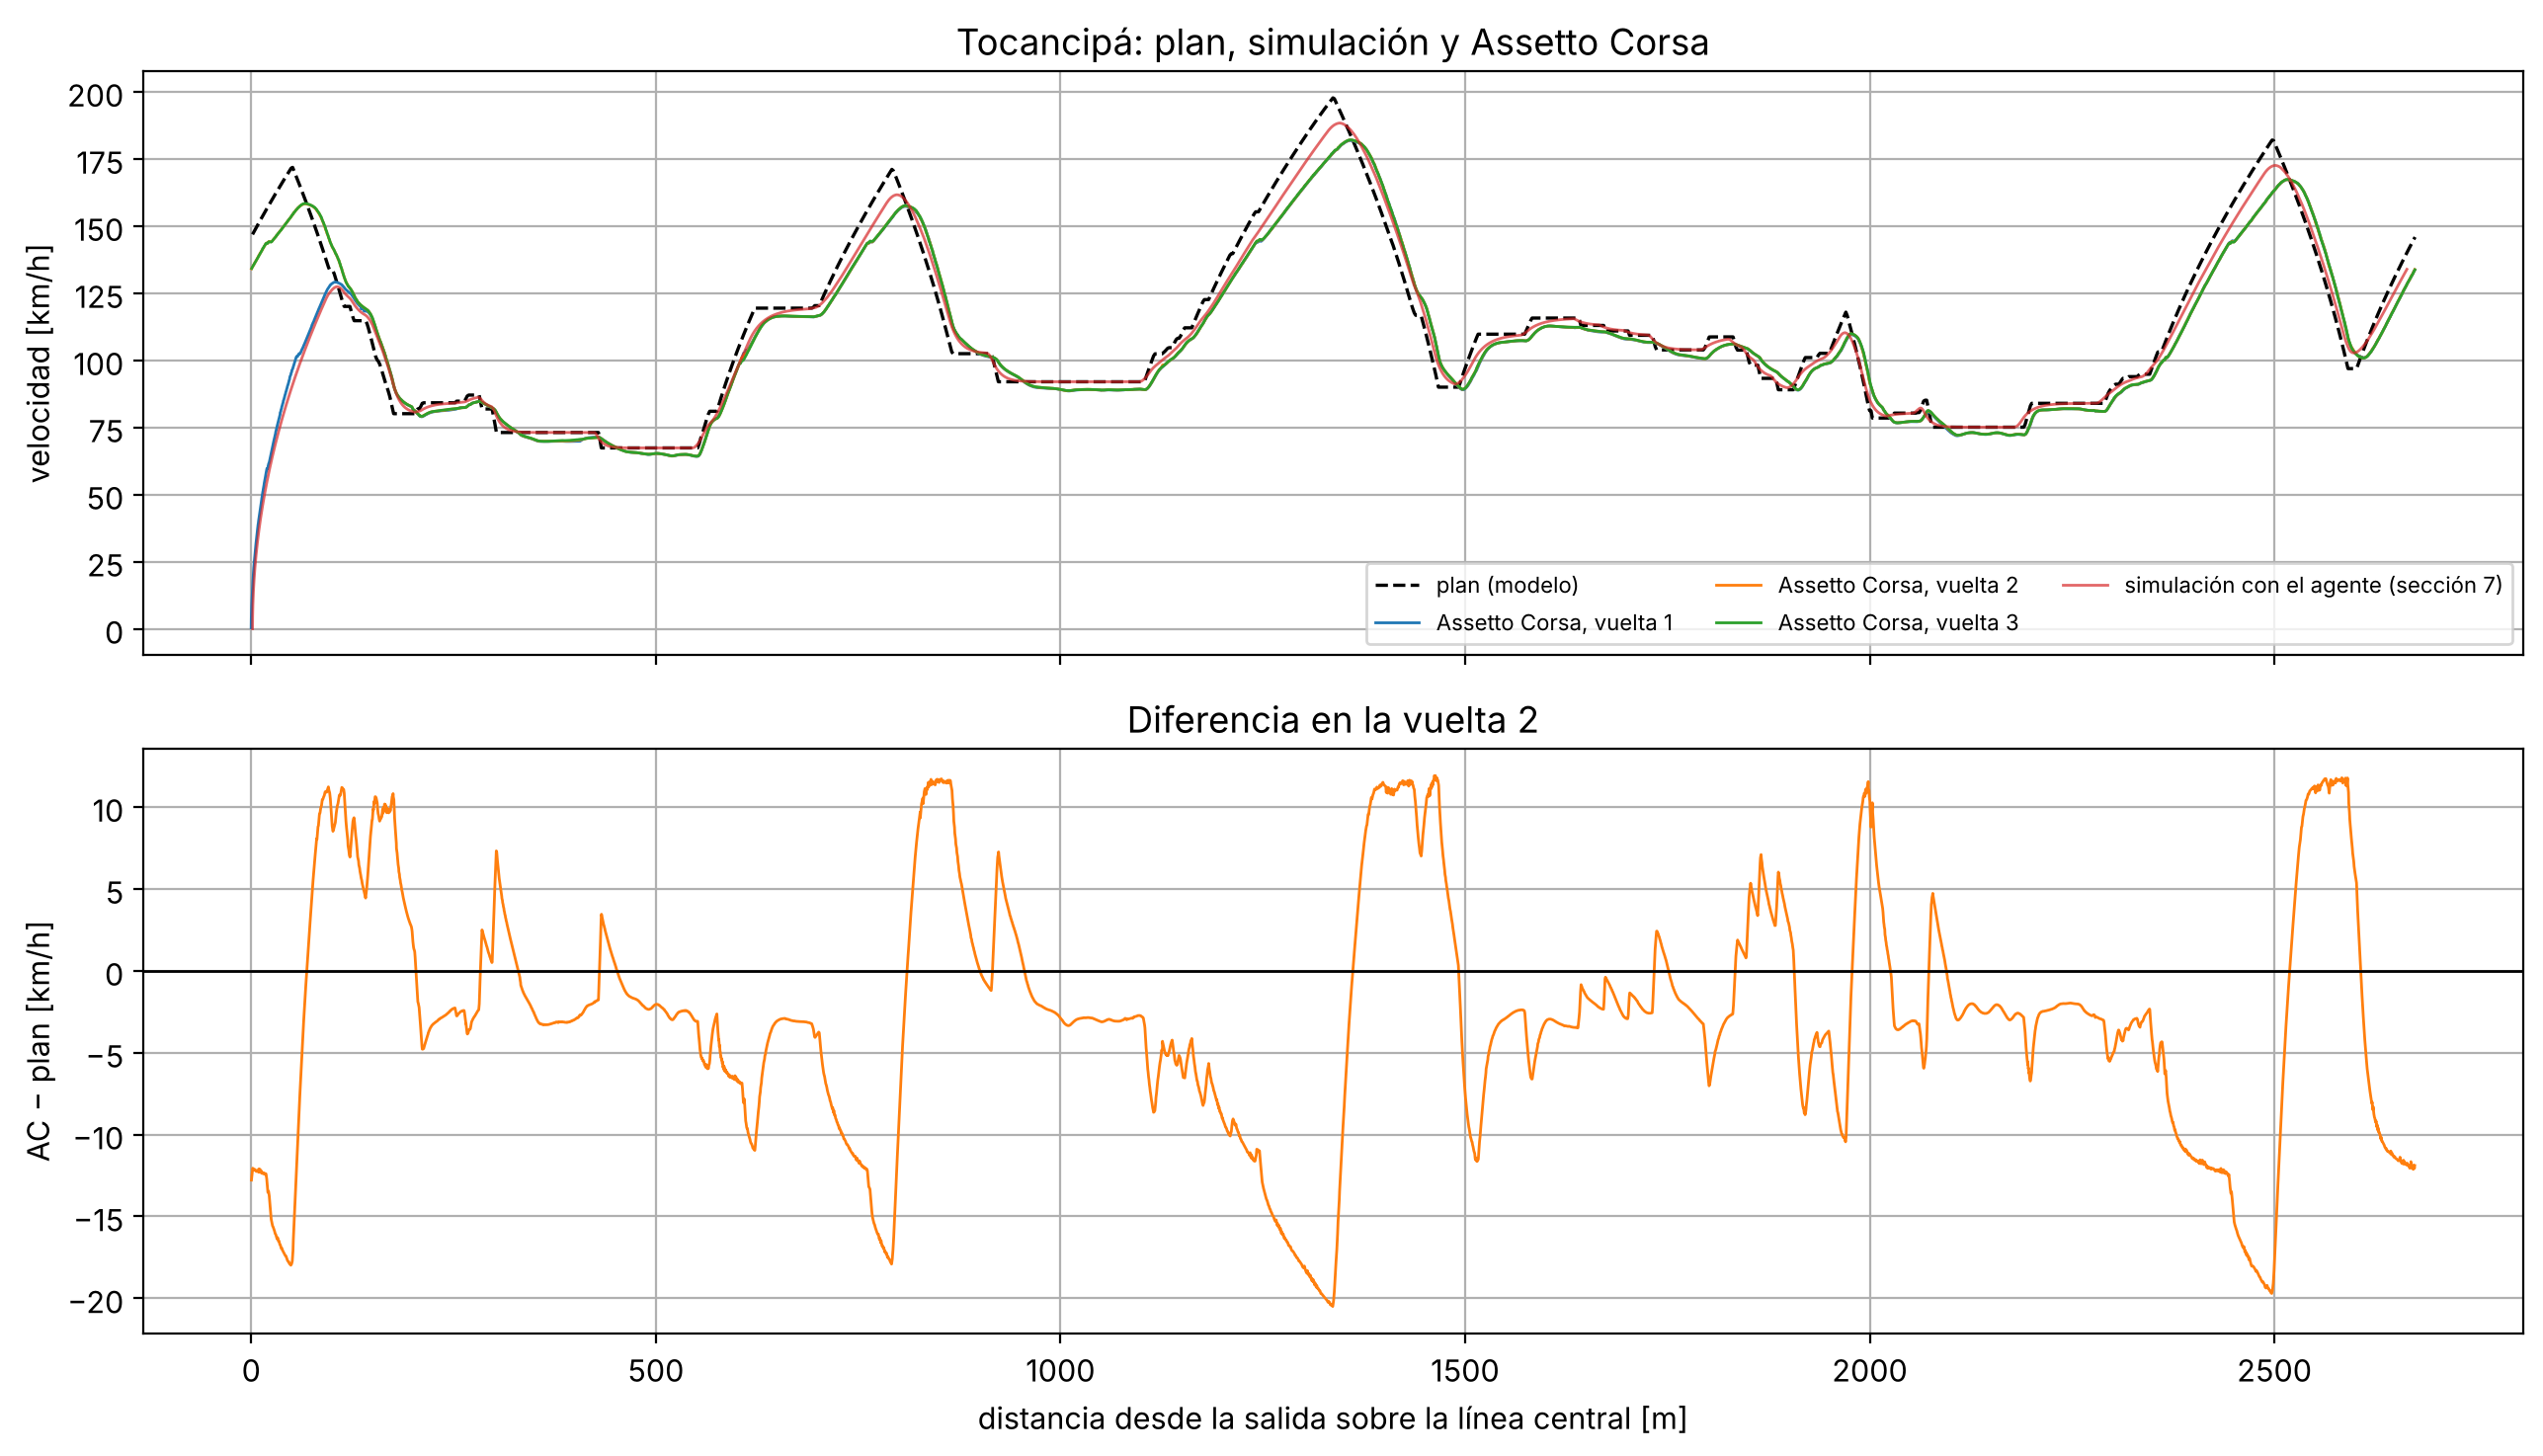

Vuelta  dif. media  dif. abs. media  % del recorrido más lento  v máx AC  dist. máx. al centro
     1      -7.5 km/h         10.1 km/h                     77 %     182 km/h             6.2 m
     2      -2.5 km/h          5.4 km/h                     75 %     182 km/h             6.0 m
     3      -2.5 km/h          5.4 km/h                     75 %     182 km/h             6.0 m
Velocidad máxima del plan: 198 km/h


In [21]:
s_plan = np.asarray(PLAN["s_centro"]) if PLAN is not None else s_c
v_plan = (np.asarray(PLAN["v"]) if PLAN is not None else evaluacion.velocidades_m_s) * 3.6
en_vuelta = (s_plan >= S_INICIO) & (s_plan <= S_META)
x_plan, v_plan = s_plan[en_vuelta] - S_INICIO, v_plan[en_vuelta]

fig, ax = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
ax[0].plot(x_plan, v_plan, "k--", lw=1.2, label="plan (modelo)")
estad = []
for n, color in [(1, "C0"), (2, "C1"), (3, "C2")]:
    sel = tel["lap"] == n
    x = dist_ac[sel] - (n - 1) * LONGITUD
    ok = (x >= 0) & (x <= LONGITUD)
    diferencia = v_ac[sel][ok] - np.interp(x[ok], x_plan, v_plan)
    estad.append((n, diferencia.mean(), np.abs(diferencia).mean(), 100 * np.mean(diferencia < 0),
                  v_ac[sel].max(), tel["lateral_error_m"][sel].max()))
    ax[0].plot(x[ok], v_ac[sel][ok], color=color, lw=1, label=f"Assetto Corsa, vuelta {n}")
    if n == 2:
        ax[1].plot(x[ok], diferencia, color=color, lw=1)
ax[0].plot(sim["s"], sim["v"] * 3.6, color="C3", lw=1, alpha=0.7, label="simulación con el agente (sección 7)")
ax[0].set(ylabel="velocidad [km/h]", title="Tocancipá: plan, simulación y Assetto Corsa"); ax[0].legend(fontsize=8, ncol=3)
ax[1].axhline(0, c="k", lw=1)
ax[1].set(xlabel="distancia desde la salida sobre la línea central [m]", ylabel="AC − plan [km/h]", title="Diferencia en la vuelta 2")
plt.tight_layout(); plt.show()

print(f"{'Vuelta':>6s} {'dif. media':>11s} {'dif. abs. media':>16s} {'% del recorrido más lento':>26s} {'v máx AC':>9s} {'dist. máx. al centro':>21s}")
for n, media, mae, lento, vmax, dmax in estad:
    print(f"{n:6d} {media:+9.1f} km/h {mae:12.1f} km/h {lento:22.0f} % {vmax:7.0f} km/h {dmax:15.1f} m")
print(f"Velocidad máxima del plan: {v_plan.max():.0f} km/h")

**Interpretación.** 
- **Dónde frenar y acelerar.** Las curvas de Assetto Corsa y del plan tienen la misma forma: frenan y aceleran en los mismos lugares. El modelo acierta el *dónde*.
- **Cuánto.** En las vueltas lanzadas, Assetto Corsa va en promedio unos 2,5 km/h por debajo del plan, con una diferencia absoluta media de unos 5 km/h, y va más lento en tres cuartas partes del recorrido.
- **Frenadas.** Justo después de cada pico, Assetto Corsa va hasta unos 10 km/h **por encima** del plan: frena más tarde. Hay dos causas: el agente reacciona con retraso (la simulación de la sección 7, con el mismo agente, hace lo mismo) y el auto frena más fuerte a alta velocidad que el $b$ constante del modelo (sección 4).
- **Plan, agente y auto.** La simulación con el agente queda entre el plan y Assetto Corsa: una parte de la diferencia viene del control y no de la física. Lo que queda entre la simulación y el juego es el error del modelo físico.
- **Rectas.** La mayor diferencia está en la velocidad máxima: el auto llega a unos 182 km/h donde el plan pide unos 198 km/h. Es lo que predice la aerodinámica que omitimos: el arrastre crece como $v^2$ y el modelo no lo tiene, así que sobreestima la velocidad al final de las rectas largas.
- **Distancia a la línea central.** Llega a unos 6 m porque la ruta optimizada se separa del centro a propósito para abrir las curvas; no es un error de seguimiento.
- **Arranque.** En la vuelta 1, la gran diferencia inicial es la salida desde cero frente a un plan lanzado.

## 12. Limitaciones

- **Modelo cinemático.** Supone que las ruedas no deslizan. No puede reproducir un derrape; solo detecta cuándo una maniobra pide más agarre del disponible (sección 7). Cerca del límite de adherencia, que es justo donde se gana tiempo, es menos fiable.
- **Parámetros constantes.** Nuestras mediciones (sección 4) muestran que el frenado real crece con la velocidad (aerodinámica), mientras el modelo usa un $b$ constante. Con eso el modelo es conservador al frenar, pero desaprovecha frenadas más tardías a alta velocidad.
- **Sin aerodinámica.** Sin arrastre, el modelo sobreestima la velocidad punta en las rectas largas: unos 198 km/h en el plan frente a unos 182 km/h en Assetto Corsa.
- **Calibración limitada.** La aceleración y el frenado salen de una sola prueba hasta 121 km/h; en la vuelta se usan constantes hasta más de 180 km/h, lo que es una extrapolación.
- **Coeficientes de los archivos del juego.** `DX_REF` y `DY_REF` son valores de referencia de un modelo de neumático mucho más complejo, no máximos garantizados durante una vuelta.
- **Geometría del mod.** La pista es una recreación hecha por la comunidad; su fidelidad al Tocancipá real depende del autor. Además la tratamos en 2D.
- **Método numérico.** Euler es de primer orden: el error es proporcional a $\Delta t$ (sección 8). Con $\Delta t = 0{,}02$ s es menor al 1 % en frenado, pero un paso mucho mayor deforma las trayectorias.
- **Perfil discreto.** La pasada hacia adelante no deja acelerar dentro de algunas curvas (perfil escalonado), así que el tiempo predicho es algo pesimista.
- **Optimización local.** La búsqueda prueba 36 formas por curva y acepta mejoras una a una; no garantiza la trayectoria óptima global.
- **Agente simple.** El agente es un controlador con reglas programadas (control proporcional y correcciones geométricas), no un piloto entrenado; su retraso explica parte de la diferencia entre el plan y lo que hace el auto, así que no todo el error es de la física.
- **Dirección.** El giro máximo de ruedas (30°) es nominal: falta verificar cómo interpreta Assetto Corsa el `STEER_LOCK` del auto.

## 13. Conclusiones

1. **Sobre la pregunta de investigación.** El modelo simplificado (bicicleta cinemática + círculo de fricción + potencia + frenado constante) sí permite predecir y optimizar trayectorias que funcionan en un simulador con física más detallada:
    - **Optimizar:** la ruta optimizada baja el tiempo predicho de la vuelta en unos 1,8 s frente a la línea central.
    - **Rendimiento:** en Assetto Corsa, las vueltas lanzadas quedaron a un 2,8 % del tiempo predicho (95,7 s frente a 93,1 s).
    - **Estabilidad:** el agente completó 3 vueltas seguidas sin desviarse de la pista, y las vueltas 2 y 3 difieren en 0,06 s.
    - **Límite del modelo:** acierta **dónde** frenar y acelerar, pero es optimista en **cuánto**, sobre todo al final de las rectas, donde pesa la aerodinámica que omitimos. En nuestra simulación, el uso del agarre supera el 100 % en algunos instantes de las curvas más exigentes: ahí está el margen de estabilidad más estrecho.
2. **Sobre el método.** Todo el modelo se basa en integrar: la pista a partir de su curvatura (que cierra la vuelta en 360°), la velocidad a lo largo de la trayectoria, el tiempo de vuelta y la posición del vehículo con la bicicleta. Esas integrales permiten decidir si una trayectoria es mejor que otra antes de manejarla.
3. **Sobre la visibilidad (análisis complementario).** La visibilidad necesaria para frenar antes de una curva crece como $v_0^2$, disminuye linealmente con el radio de la curva ($-R/2$) y es inversamente proporcional a $\mu$. En la vuelta, conocer más pista que la distancia de frenado más larga ya no mejora el tiempo.
4. **Sobre la confiabilidad numérica.** Euler explícito es de primer orden: el error en la distancia de frenado es $\approx \tfrac{1}{2}v_0\Delta t$, comprobado numéricamente. Con $\Delta t = 0{,}02$ s el error es menor al 1 % y el tiempo de vuelta cambia poco al reducir el paso.
5. **Sobre los datos propios.** Medir en el simulador mostró que el frenado real depende de la velocidad, y la comparación de vueltas mostró una velocidad punta menor que la del plan. Ambos apuntan al mismo término que agregaríamos primero: arrastre y carga aerodinámica proporcionales a $v^2$.

## 14. Declaración de uso de IA

| Herramienta | Uso |
|---|---|
| Claude (Anthropic) | Redacción de las explicaciones de aspectos, simplificaciones y fenómenos omitidos; estructura de este notebook; texto explicativo y código de análisis del notebook (secciones 4 a 11: carga de datos, reconstrucción de la pista, ápices, simulación con el agente, validaciones, visibilidad, sensibilidad y comparación con la telemetría), que importa y usa los módulos del proyecto. Guion de la sustentación. |
| ✍️ *(completar)* | Herramientas usadas para escribir o documentar los módulos de `proy entrega final/` y el comparador, si las hubo. |

Todo el contenido fue revisado por el grupo y cualquier parte puede ser objeto de preguntas en la sustentación.

## 15. Referencias

- Kunos Simulazioni. *Assetto Corsa* (2014).
- Autódromo de Tocancipá 2.0, mod para Assetto Corsa hecho para la APVS (Asociación de Pilotos Virtuales Sudamericanos).
- Datos del circuito real (longitud, número de curvas y desnivel): LapMeta, ficha del Autódromo de Tocancipá.
- *A Simulation Benchmark for Autonomous Racing* (Assetto Corsa Gym), arXiv:2407.16680 (2024).
- ✍️ Agregar: texto guía del curso y el artículo usado para las ecuaciones de geometría (`integrar_pista_desde_curvatura_paper`).